In [3]:
import os, sys, json, time, math, random, glob, platform, inspect, warnings, zlib, contextlib
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix, save_npz, load_npz, vstack
from scipy.stats import spearmanr, mannwhitneyu
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

MODEL_DIR = Path("/kaggle/input/datasets/ulianaandrosova/splade-max/splade-baseline-encoder")
DATA_DIR = Path("/kaggle/input/datasets/parthplc/ms-marco-dataset")
OUT_DIR = Path("/kaggle/working/attack_results")
PLOT_DIR = OUT_DIR / "plots"
TABLE_DIR = OUT_DIR / "tables"
RECORD_DIR = OUT_DIR / "records"
for d in (OUT_DIR, PLOT_DIR, TABLE_DIR, RECORD_DIR, OUT_DIR / "index"):
    d.mkdir(parents=True, exist_ok=True)


PRESET = "default"

PRESETS = {
    "smoke": dict(pool_queries=60, n_length=3, n_position=3, n_multi=3, lengths=[1, 3, 5], restarts=2, max_iters=3,
                  position_restarts=1, docs_per_query=2, multi_restarts=1, n_random_seeds=2,
                  n_global_batches=1, global_batch_size=4, global_restarts=1, global_heldout=8,
                  loo_records=30, transfer_tokens=5, transfer_pairs=20, text_check=30, sanity_queries=100),
    "default": dict(pool_queries=400, n_length=20, n_position=15, n_multi=15, lengths=[1, 3, 5], restarts=2, max_iters=10,
                    position_restarts=1, docs_per_query=4, multi_restarts=1, n_random_seeds=5,
                    n_global_batches=3, global_batch_size=8, global_restarts=1, global_heldout=48,
                    loo_records=300, transfer_tokens=30, transfer_pairs=200, text_check=300, sanity_queries=500),
    "full": dict(pool_queries=1000, n_length=100, n_position=100, n_multi=100, lengths=[1, 3, 5, 7, 9], restarts=6, max_iters=20,
                 position_restarts=6, docs_per_query=10, multi_restarts=1, n_random_seeds=5,
                 n_global_batches=10, global_batch_size=32, global_restarts=3, global_heldout=200,
                 loo_records=1000, transfer_tokens=50, transfer_pairs=500, text_check=1000, sanity_queries=2000),
}
CFG = dict(PRESETS[PRESET])
CFG.update(
    preset=PRESET,
    seed=42,
    rank_depth=100,           
    num_candidates=40,         
    beam_size=1,               
    position_trigger_len=5,    
    position_max_iters=10,     
    multi_trigger_len=3,       
    multi_max_iters=10,       
    position_modes=["start", "middle", "end", "random", "max_grad", "min_grad"],
    rel_max_rank=10,          
    query_batch_size=8,
    doc_batch_size=8,
    token_budget=8192,         
    calibration_docs=16,
    min_calibration_cos=0.999, 
    amp_search=True,           
    resume=True,              
)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def rng_for(*parts):
    """Свой генератор для каждой атаки: результат не зависит от порядка и от перезапуска."""
    key = "|".join(str(p) for p in parts)
    return np.random.default_rng([CFG["seed"], zlib.crc32(key.encode())])


seed_everything(CFG["seed"])
RUNTIME = []  
print("Preset:", PRESET)
print(json.dumps({k: v for k, v in CFG.items() if k != "position_modes"}, ensure_ascii=False))

Preset: default
{"pool_queries": 400, "n_length": 20, "n_position": 15, "n_multi": 15, "lengths": [1, 3, 5], "restarts": 2, "max_iters": 10, "position_restarts": 1, "docs_per_query": 4, "multi_restarts": 1, "n_random_seeds": 5, "n_global_batches": 3, "global_batch_size": 8, "global_restarts": 1, "global_heldout": 48, "loo_records": 300, "transfer_tokens": 30, "transfer_pairs": 200, "text_check": 300, "sanity_queries": 500, "preset": "default", "seed": 42, "rank_depth": 100, "num_candidates": 40, "beam_size": 1, "position_trigger_len": 5, "position_max_iters": 10, "multi_trigger_len": 3, "multi_max_iters": 10, "rel_max_rank": 10, "query_batch_size": 8, "doc_batch_size": 8, "token_budget": 8192, "calibration_docs": 16, "min_calibration_cos": 0.999, "amp_search": true, "resume": true}


In [4]:
t0 = time.time()
print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert (MODEL_DIR / "model" / "model.pt").exists(), "Checkpoint не найден"
assert (DATA_DIR / "train.csv").exists(), "train.csv не найден"
assert (DATA_DIR / "valid.csv").exists(), "valid.csv не найден"

sys.path.insert(0, str(MODEL_DIR))
from splade import Splade

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Splade(model_dir=str(MODEL_DIR / "model"), device=device)
tokenizer = model.tokenizer
VOCAB = model.model.config.vocab_size

print("Device:", device)
print("Vocab size:", VOCAB)
print("Model max positions:", model.model.config.max_position_embeddings)
print("Tokenizer:", type(tokenizer).__name__, getattr(tokenizer, "name_or_path", ""))

try:
    src = inspect.getsource(Splade)
    print("\n---- splade.Splade (первые 80 строк) ----")
    print("\n".join(src.splitlines()[:80]))
except (OSError, TypeError) as e:
    print("Исходник Splade недоступен:", e)
print("\nМетоды Splade:", [m for m in dir(model) if not m.startswith("_")])
print("Целые атрибуты Splade:", {k: v for k, v in vars(model).items() if isinstance(v, (int, float, str, bool))})


def find_doc_mlm(obj):
    """HF-модель, которая кодирует документы: ищем модуль с get_input_embeddings() и config."""
    for name in ("doc_model", "document_model", "d_model", "doc_encoder", "model"):
        m = getattr(obj, name, None)
        if isinstance(m, torch.nn.Module):
            for sub in m.modules():
                if hasattr(sub, "get_input_embeddings") and hasattr(sub, "config"):
                    return name, sub
    raise RuntimeError("Не нашёл внутри Splade HF-модель с get_input_embeddings(); посмотрите исходник выше")


MLM_ATTR, MLM = find_doc_mlm(model)
MLM.eval()
for p in MLM.parameters():
    p.requires_grad_(False)   
EMB_LAYER = MLM.get_input_embeddings()
EMB_W = EMB_LAYER.weight.detach()
EMB_W_F = EMB_W.float()
ACCEPTS_TT = "token_type_ids" in inspect.signature(MLM.forward).parameters
print(f"\nДокументы кодирует model.{MLM_ATTR}: {type(MLM).__name__}, эмбеддинги {tuple(EMB_W.shape)}, dtype {EMB_W.dtype}")

vocab_tokens = tokenizer.convert_ids_to_tokens(list(range(VOCAB)))
VOCAB_MIN_ID = next(i for i, t in enumerate(vocab_tokens) if not (t.startswith("[") and t.endswith("]")))
CLS_ID, SEP_ID, PAD_ID, MASK_ID = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.mask_token_id
SPECIAL_IDS = sorted(set(tokenizer.all_special_ids))
ALLOWED_MASK = torch.ones(VOCAB, dtype=torch.bool, device=device)
ALLOWED_MASK[:VOCAB_MIN_ID] = False
ALLOWED_MASK[torch.tensor(SPECIAL_IDS, device=device)] = False
ALLOWED_IDS = torch.nonzero(ALLOWED_MASK).flatten().cpu().numpy()
print("Первый обычный токен словаря:", VOCAB_MIN_ID, repr(vocab_tokens[VOCAB_MIN_ID]), "| кандидатов для триггера:", len(ALLOWED_IDS))
RUNTIME.append(("model_load", time.time() - t0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda
Vocab size: 30522
Model max positions: 512
Tokenizer: DistilBertTokenizer /kaggle/input/datasets/ulianaandrosova/splade-max/splade-baseline-encoder/model

---- splade.Splade (первые 80 строк) ----
class Splade:
    def __init__(self, model_dir=None, device="cpu"):
        model_dir = Path(model_dir) if model_dir else Path(__file__).parent / "model"
        self.device = torch.device(device)
        config = AutoConfig.from_pretrained(model_dir, local_files_only=True)
        self.model = AutoModelForMaskedLM.from_config(config)
        state = torch.load(model_dir / "model.pt", map_location="cpu", weights_only=True)
        self.model.load_state_dict(state, strict=True)
        self.model.to(self.device).eval()
        self.tokenizer = AutoTokenizer.from_pretrained(model_dir, local_files_only=True)

    @torch.in

In [5]:
t0 = time.time()
train = pd.read_csv(DATA_DIR / "train.csv")
valid = pd.read_csv(DATA_DIR / "valid.csv")

required_columns = {"query", "finalpassage"}
for name, frame in [("train", train), ("valid", valid)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name}.csv: отсутствуют колонки {sorted(missing)}")

data = pd.concat([train, valid], ignore_index=True)
data = data.dropna(subset=["query", "finalpassage"]).copy()
data["query"] = data["query"].astype(str).str.strip()
data["finalpassage"] = data["finalpassage"].astype(str).str.strip()
data = data[(data["query"] != "") & (data["finalpassage"] != "")]

documents = (
    data[["finalpassage"]]
    .drop_duplicates(subset=["finalpassage"])
    .reset_index(drop=True)
)
documents["doc_id"] = np.arange(len(documents), dtype=np.int64)

queries = (
    data[["query"]]
    .drop_duplicates(subset=["query"])
    .reset_index(drop=True)
)
queries["query_id"] = np.arange(len(queries), dtype=np.int64)

# ---- фаза 2: пары «запрос → релевантный документ» из той же разметки ----
pairs = (data[["query", "finalpassage"]]
         .merge(queries, on="query")
         .merge(documents, on="finalpassage")[["query_id", "doc_id"]]
         .drop_duplicates())
qrels = pairs.groupby("query_id")["doc_id"].apply(lambda s: set(int(x) for x in s)).to_dict()
doc_texts = documents["finalpassage"].tolist()
query_text = dict(zip(queries["query_id"].astype(int), queries["query"]))

data_summary = pd.DataFrame([
    ("Строк после очистки", len(data)),
    ("Документов в корпусе", len(documents)),
    ("Уникальных запросов", len(queries)),
    ("Пар запрос–релевантный документ", len(pairs)),
    ("Запросов с ≥ 2 релевантными", sum(len(v) > 1 for v in qrels.values())),
], columns=["Показатель", "Значение"])
display(data_summary)
RUNTIME.append(("data", time.time() - t0))

,Показатель,Значение
0,Строк после очистки,130560
1,Документов в корпусе,130500
2,Уникальных запросов,130551
3,Пар запрос–релевантный документ,130560
4,Запросов с ≥ 2 релевантными,9


In [6]:
t0 = time.time()


def locate_artifact(name):
    for d in (OUT_DIR / "index", Path("/kaggle/working/wacky_results"), OUT_DIR):
        p = d / name
        if p.exists():
            return p
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    return Path(hits[0]) if hits else None


INDEX_NAME = "splade_document_index.npz"
index_path = locate_artifact(INDEX_NAME)
doc_matrix = None
index_source = None
if index_path is not None:
    doc_matrix = load_npz(index_path).tocsr()
    if doc_matrix.shape != (len(documents), VOCAB):
        print(f"Индекс {index_path} не совпадает с корпусом: {doc_matrix.shape}; пересобираю")
        doc_matrix = None
    else:
        index_source = f"найден готовый: {index_path}"

if doc_matrix is None:
    # Тот же код, что в фазе 1
    INDEX_PATH = OUT_DIR / "index" / INDEX_NAME
    BATCH_SIZE = CFG["doc_batch_size"]
    sparse_batches = []
    for start in tqdm(range(0, len(doc_texts), BATCH_SIZE), desc="Encoding documents"):
        batch_texts = doc_texts[start:start + BATCH_SIZE]
        vectors = model.encode_documents(
            batch_texts,
            batch_size=BATCH_SIZE
        ).numpy().astype(np.float32, copy=False)
        sparse_batches.append(csr_matrix(vectors))
        del vectors
    doc_matrix = vstack(sparse_batches, format="csr", dtype=np.float32)
    del sparse_batches
    doc_matrix.eliminate_zeros()
    save_npz(INDEX_PATH, doc_matrix, compressed=True)
    index_path = INDEX_PATH
    index_source = "пересобран в фазе 2 кодом фазы 1"

splade_df = np.asarray(doc_matrix.getnnz(axis=0)).ravel().astype(np.int64)
print("Индекс:", index_source)
print("Sparse index shape:", doc_matrix.shape)
print("Stored nonzero weights:", doc_matrix.nnz)
print("Mean active terms/document:", round(doc_matrix.getnnz(axis=1).mean(), 2))

wacky_path = locate_artifact("wackiness_scores_repo_aligned.csv")
lexical_path = locate_artifact("lexical_token_df_idf.csv")
wacky_table = pd.read_csv(wacky_path) if wacky_path else None
lexical_table = pd.read_csv(lexical_path) if lexical_path else None
print("Wackiness фазы 1:", wacky_path or "не найдено — колонки wackiness будут пустыми")
print("Лексический DF фазы 1:", lexical_path or "не найдено")
RUNTIME.append(("index", time.time() - t0))

Encoding documents:   0%|          | 0/16313 [00:00<?, ?it/s]

Индекс: пересобран в фазе 2 кодом фазы 1
Sparse index shape: (130500, 30522)
Stored nonzero weights: 24771232
Mean active terms/document: 189.82
Wackiness фазы 1: не найдено — колонки wackiness будут пустыми
Лексический DF фазы 1: не найдено


In [7]:
t0 = time.time()


def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().float().cpu().numpy()
    return np.asarray(x, dtype=np.float32)


def mlm_logits(keep_dtype=False, **kwargs):
    out = MLM(**kwargs)
    logits = out.logits if hasattr(out, "logits") else out[0]
    return logits if (keep_dtype or logits.dtype == torch.float32) else logits.float()


def search_precision(fast):
    """float16 только для перебора кандидатов; измерения — всегда в float32."""
    if fast and CFG["amp_search"] and device == "cuda":
        return torch.autocast("cuda", dtype=torch.float16)
    return contextlib.nullcontext()


def splade_aggregate(logits, attn, agg, inplace=False):
    mask = attn.unsqueeze(-1).to(logits.dtype)
    if inplace:
        act = logits.relu_().log1p_().mul_(mask)
    else:
        act = torch.log1p(torch.relu(logits)) * mask
    return act.amax(dim=1) if agg == "max" else act.sum(dim=1)


def model_inputs(ids, attn, embeds=None):
    kw = {"attention_mask": attn}
    if embeds is None:
        kw["input_ids"] = ids
    else:
        kw["inputs_embeds"] = embeds
    if ACCEPTS_TT:
        kw["token_type_ids"] = torch.zeros_like(ids)
    return kw



cal_rng = np.random.default_rng(CFG["seed"])
probe = cal_rng.choice(len(doc_texts), size=min(3000, len(doc_texts)), replace=False)
probe_len = np.array([len(tokenizer.encode(doc_texts[i], add_special_tokens=False, verbose=False)) for i in probe])
half = CFG["calibration_docs"] // 2
cal_ids = list(probe[np.argsort(-probe_len)[:half]]) + list(cal_rng.choice(probe, size=CFG["calibration_docs"] - half, replace=False))
cal_texts = [doc_texts[int(i)] for i in cal_ids]
print("Длина документов в токенах (образец 3000): медиана", int(np.median(probe_len)), "| 95%", int(np.percentile(probe_len, 95)),
      "| максимум", int(probe_len.max()))

ref = to_numpy(model.encode_documents(cal_texts, batch_size=CFG["doc_batch_size"]))
ref_norm = np.linalg.norm(ref, axis=1) + 1e-12

cand_lengths = {128, 200, 256, 300, 512}
for k, v in vars(model).items():
    if isinstance(v, int) and not isinstance(v, bool) and "len" in k.lower() and 8 <= v <= 4096:
        cand_lengths.add(v)
tml = getattr(tokenizer, "model_max_length", None)
if isinstance(tml, int) and 8 <= tml <= 4096:
    cand_lengths.add(tml)
cand_lengths = sorted(L for L in cand_lengths if L <= model.model.config.max_position_embeddings)

calib_rows = []
with torch.no_grad():
    for agg in ("max", "sum"):
        for L in cand_lengths:
            enc = tokenizer(cal_texts, truncation=True, max_length=L, padding=True, return_tensors="pt").to(device)
            logits = mlm_logits(**model_inputs(enc["input_ids"], enc["attention_mask"]))
            rep = to_numpy(splade_aggregate(logits, enc["attention_mask"], agg, inplace=True))
            cos = (rep * ref).sum(1) / (np.linalg.norm(rep, axis=1) * ref_norm + 1e-12)
            calib_rows.append(dict(agg=agg, max_length=L, cos_min=float(cos.min()), cos_mean=float(cos.mean()),
                                   max_abs_diff=float(np.abs(rep - ref).max()),
                                   rel_l1=float(np.abs(rep - ref).sum() / (np.abs(ref).sum() + 1e-12)),
                                   nnz_adapter=float((rep > 0).sum(1).mean()), nnz_reference=float((ref > 0).sum(1).mean())))
            del logits
calibration = pd.DataFrame(calib_rows).sort_values(["cos_min", "max_abs_diff"], ascending=[False, True]).reset_index(drop=True)
calibration.to_csv(TABLE_DIR / "calibration.csv", index=False)
display(calibration.round(6))

best_cal = calibration.iloc[0]
DOC_AGG, DOC_MAXLEN = str(best_cal["agg"]), int(best_cal["max_length"])
if best_cal["cos_min"] < CFG["min_calibration_cos"]:
    raise RuntimeError(
        f"Дифференцируемый SPLADE не совпал с model.encode_documents (лучший cos_min={best_cal['cos_min']:.5f}). "
        "Посмотрите исходник Splade выше: как он токенизирует, агрегирует и нормирует; поправьте splade_aggregate или "
        "min_calibration_cos в CFG.")
BODY_MAX = DOC_MAXLEN - 2
print(f"Выбрано: агрегация {DOC_AGG}, max_length {DOC_MAXLEN}; cos_min {best_cal['cos_min']:.6f}, max|Δ| {best_cal['max_abs_diff']:.2e}")

for t in cal_texts:
    a = tokenizer(t, truncation=True, max_length=DOC_MAXLEN)["input_ids"]
    b = [CLS_ID] + tokenizer.encode(t, add_special_tokens=False, verbose=False)[:BODY_MAX] + [SEP_ID]
    assert a == b, "Токенизация тела документа расходится с tokenizer(...)"
print("Токенизация тела документа совпадает с tokenizer(...).")
RUNTIME.append(("calibration", time.time() - t0))

Длина документов в токенах (образец 3000): медиана 154 | 95% 271 | максимум 404


,agg,max_length,cos_min,cos_mean,max_abs_diff,rel_l1,nnz_adapter,nnz_reference
0,max,256,1.000000,1.000000,0.000009,0.000002,219.3750,219.375
1,max,300,0.941501,0.984220,1.476320,0.102479,225.8125,219.375
2,max,512,0.929239,0.974699,1.499623,0.155243,232.0000,219.375
3,max,200,0.864432,0.961603,2.008682,0.179833,199.8750,219.375
4,max,128,0.794329,0.896534,2.228098,0.366659,167.2500,219.375
5,sum,256,0.426101,0.562175,232.977646,3.722887,219.3750,219.375
6,sum,128,0.420987,0.565062,102.796013,2.325235,167.2500,219.375
7,sum,300,0.415109,0.555398,236.889511,4.112186,225.8125,219.375
8,sum,512,0.405666,0.545150,238.642532,4.436234,232.0000,219.375
9,sum,200,0.377405,0.561997,200.235001,3.135098,199.8750,219.375


Выбрано: агрегация max, max_length 256; cos_min 1.000000, max|Δ| 9.48e-06
Токенизация тела документа совпадает с tokenizer(...).


In [8]:

TOKEN_BUDGET = CFG["token_budget"]
FORWARD_STATS = Counter()
_body_cache = {}


def doc_body(doc_id):
    """Токены документа без [CLS]/[SEP], обрезанные так же, как при кодировании."""
    doc_id = int(doc_id)
    if doc_id not in _body_cache:
        _body_cache[doc_id] = tokenizer.encode(doc_texts[doc_id], add_special_tokens=False, verbose=False)[:BODY_MAX]
    return list(_body_cache[doc_id])


def pack(bodies):
    seqs = [[CLS_ID] + [int(x) for x in b][:BODY_MAX] + [SEP_ID] for b in bodies]
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    attn = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s, dtype=torch.long)
        attn[i, :len(s)] = 1
    return ids.to(device), attn.to(device)


def _chunks(lengths, budget):
    chunk, cur = [], 0
    for i, l in enumerate(lengths):
        m = max(cur, l)
        if chunk and m * (len(chunk) + 1) > budget:
            yield chunk
            chunk, m = [], l
        chunk.append(i)
        cur = m
    if chunk:
        yield chunk


@torch.no_grad()
def splade_reps(bodies, fast=False):
    ids, attn = pack(bodies)
    with search_precision(fast):
        logits = mlm_logits(keep_dtype=fast, **model_inputs(ids, attn))
        rep = splade_aggregate(logits, attn, DOC_AGG, inplace=True)
    FORWARD_STATS["doc_forwards_fp16" if fast and CFG["amp_search"] and device == "cuda" else "doc_forwards"] += len(bodies)
    return rep.float()


def score_bodies(bodies, qv, q_rows=None, fast=False):
    """Score документов (списки token id). qv: [V] — один запрос; или [m, V] и q_rows — строка запроса для каждого документа.
    fast=True — перебор кандидатов в float16 (только для выбора, не для записи результатов)."""
    global TOKEN_BUDGET
    out = np.empty(len(bodies), dtype=np.float64)
    lengths = [min(len(b), BODY_MAX) + 2 for b in bodies]
    pending = list(_chunks(lengths, TOKEN_BUDGET))
    while pending:
        idx = pending.pop(0)
        try:
            rep = splade_reps([bodies[i] for i in idx], fast=fast)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if len(idx) == 1:
                raise
            TOKEN_BUDGET = max(512, TOKEN_BUDGET // 2)
            pending = [idx[:len(idx) // 2], idx[len(idx) // 2:]] + pending
            continue
        if qv.dim() == 1:
            sc = rep @ qv
        else:
            rows = torch.as_tensor([q_rows[i] for i in idx], device=qv.device)
            sc = (rep * qv[rows]).sum(1)
        out[idx] = sc.double().cpu().numpy()
        del rep
    return out


def score_and_grad(body, qv):
    """Score и градиент по входным эмбеддингам тела документа: [n_body, H]."""
    ids, attn = pack([body])
    with torch.no_grad():
        base = EMB_LAYER(ids)
    emb = base.detach().clone().requires_grad_(True)
    logits = mlm_logits(**model_inputs(ids, attn, embeds=emb))
    rep = splade_aggregate(logits, attn, DOC_AGG)
    score = (rep[0] * qv).sum()
    score.backward()
    FORWARD_STATS["grad_passes"] += 1
    n = min(len(body), BODY_MAX)
    return float(score.item()), emb.grad[0, 1:1 + n].detach().float()


def encode_queries(texts):
    bs = CFG["query_batch_size"]
    out = [to_numpy(model.encode_queries(texts[s:s + bs], batch_size=bs)) for s in range(0, len(texts), bs)]
    return np.vstack(out).astype(np.float32)


def sparse_topk(query_vector, k):
    q_sparse = csr_matrix(np.asarray(query_vector, dtype=np.float32).reshape(1, -1))
    scores_sparse = (q_sparse @ doc_matrix.T).tocsr()
    if scores_sparse.nnz == 0:
        return np.empty(0, dtype=np.int64), np.empty(0, dtype=np.float32)
    candidate_ids = scores_sparse.indices
    candidate_scores = scores_sparse.data
    order = np.argsort(candidate_scores)[::-1][:min(k, len(candidate_ids))]
    return candidate_ids[order].astype(np.int64), candidate_scores[order].astype(np.float32)


def rank_of(score, others):
    """Позиция (0 — первая) документа со score среди остальных документов списка."""
    return int(np.sum(np.asarray(others) > score))


def normalized_rank_shift(direction, orig_pos, new_pos, n):
    """get_accuracy из attack_trigger_multiple_docs.py."""
    try:
        if direction == "demotion":
            return (new_pos - orig_pos) / (n - 1 - orig_pos)
        return (orig_pos - new_pos) / orig_pos
    except ZeroDivisionError:
        return 0.0


def save_table(df, name, show=True, round_=4):
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    if show:
        display(df.round(round_) if round_ is not None else df)


def savefig(fig, name):
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print("Функции адаптера готовы. Бюджет токенов на батч:", TOKEN_BUDGET)

Функции адаптера готовы. Бюджет токенов на батч: 8192


In [9]:
t0 = time.time()
srng = np.random.default_rng(CFG["seed"] + 7)
all_qids = np.array(sorted(qrels))
san_ids = srng.choice(all_qids, size=min(CFG["sanity_queries"], len(all_qids)), replace=False)
san_vecs = encode_queries([query_text[int(q)] for q in san_ids])

rr10, r10, r100, r1000, active_terms = [], [], [], [], []
for qid, qv in zip(tqdm(san_ids, desc="Retrieval sanity"), san_vecs):
    ids, _ = sparse_topk(qv, 1000)
    rel = qrels[int(qid)]
    ranks = [r for r, d in enumerate(ids) if int(d) in rel]
    first = ranks[0] if ranks else None
    rr10.append(1.0 / (first + 1) if first is not None and first < 10 else 0.0)
    r10.append(float(first is not None and first < 10))
    r100.append(float(first is not None and first < 100))
    r1000.append(float(first is not None))
    active_terms.append(int((qv > 0).sum()))
retrieval_sanity = {"queries": int(len(san_ids)), "MRR@10": float(np.mean(rr10)), "Recall@10": float(np.mean(r10)),
                    "Recall@100": float(np.mean(r100)), "Recall@1000": float(np.mean(r1000)),
                    "mean_active_query_terms": float(np.mean(active_terms))}
display(pd.DataFrame([retrieval_sanity]).round(4))
with open(OUT_DIR / "retrieval_sanity.json", "w", encoding="utf-8") as f:
    json.dump(retrieval_sanity, f, indent=2, ensure_ascii=False)


agree_rows = []
for qid, qv in list(zip(san_ids, san_vecs))[:20]:
    ids, sc_index = sparse_topk(qv, 10)
    qv_t = torch.from_numpy(qv).to(device)
    sc_adapter = score_bodies([doc_body(d) for d in ids], qv_t)
    agree_rows.append(dict(query_id=int(qid), max_abs_diff=float(np.abs(sc_adapter - sc_index).max()),
                           max_rel_diff=float((np.abs(sc_adapter - sc_index) / (np.abs(sc_index) + 1e-9)).max()),
                           spearman=float(spearmanr(sc_adapter, sc_index).correlation) if len(ids) > 2 else np.nan,
                           top1_same=bool(np.argmax(sc_adapter) == 0)))
score_agreement = pd.DataFrame(agree_rows)
save_table(score_agreement.describe().T.reset_index().rename(columns={"index": "metric"}), "sanity_index_vs_adapter")

qv_t = torch.from_numpy(san_vecs[0]).to(device)
b = doc_body(sparse_topk(san_vecs[0], 1)[0][0])
s_ids = score_bodies([b], qv_t)[0]
s_emb, _ = score_and_grad(b, qv_t)
print(f"score через input_ids {s_ids:.6f}, через inputs_embeds {s_emb:.6f}, |Δ| {abs(s_ids - s_emb):.2e}")
assert abs(s_ids - s_emb) <= 1e-3 * max(1.0, abs(s_ids)), "Пути через input_ids и inputs_embeds расходятся"

fo_rows = []
for qid, qv in list(zip(san_ids, san_vecs))[:12]:
    ids, _ = sparse_topk(qv, 10)
    if len(ids) == 0:
        continue
    qv_t = torch.from_numpy(qv).to(device)
    body0 = doc_body(ids[0])
    base_body = [MASK_ID] + body0
    s_base, g = score_and_grad(base_body, qv_t)
    g0 = g[0]
    cands = np.concatenate([
        torch.topk(g0 @ EMB_W_F.T, 20).indices.cpu().numpy(),
        torch.topk(-(g0 @ EMB_W_F.T), 20).indices.cpu().numpy(),
        srng.choice(ALLOWED_IDS, 20, replace=False)])
    pred = ((EMB_W_F[torch.as_tensor(cands, device=device)] - EMB_W_F[MASK_ID]) @ g0).cpu().numpy()
    actual = score_bodies([[int(c)] + body0 for c in cands], qv_t) - s_base
    fo_rows.append(dict(query_id=int(qid), spearman=float(spearmanr(pred, actual).correlation),
                        sign_agreement=float(np.mean(np.sign(pred) == np.sign(actual))),
                        mean_abs_actual=float(np.abs(actual).mean())))
first_order = pd.DataFrame(fo_rows)
save_table(first_order.describe().T.reset_index().rename(columns={"index": "metric"}), "sanity_first_order")
RUNTIME.append(("sanity", time.time() - t0))

Retrieval sanity:   0%|          | 0/500 [00:00<?, ?it/s]

,queries,MRR@10,Recall@10,Recall@100,Recall@1000,mean_active_query_terms
0,500,0.7761,0.942,0.992,0.998,20.788


,metric,count,mean,std,min,25%,50%,75%,max
0,query_id,20.0,67449.35,36505.9884,7682.0,42631.75,62936.5,102677.5,129526.0
1,max_abs_diff,20.0,0.00,0.0000,0.0,0.00,0.0,0.0,0.0
2,max_rel_diff,20.0,0.00,0.0000,0.0,0.00,0.0,0.0,0.0
3,spearman,20.0,1.00,0.0000,1.0,1.00,1.0,1.0,1.0


score через input_ids 15.142243, через inputs_embeds 15.142245, |Δ| 1.91e-06


,metric,count,mean,std,min,25%,50%,75%,max
0,query_id,12.0,62179.9167,38658.7897,7682.0000,25843.0000,62936.5000,102677.5000,114881.0000
1,spearman,12.0,0.5734,0.1177,0.4314,0.4982,0.5318,0.6418,0.7983
2,sign_agreement,12.0,0.6681,0.1156,0.4833,0.5667,0.6917,0.7292,0.8667
3,mean_abs_actual,12.0,0.3341,0.1739,0.1237,0.1939,0.2816,0.4710,0.6204


In [10]:
t0 = time.time()
prng = np.random.default_rng(CFG["seed"] + 11)
pool_ids = prng.choice(all_qids, size=min(CFG["pool_queries"], len(all_qids)), replace=False)
pool_vecs = encode_queries([query_text[int(q)] for q in pool_ids])

RANKLISTS = {}
for qid, qv in zip(tqdm(pool_ids, desc="Ranking lists"), pool_vecs):
    qid = int(qid)
    ids, scores = sparse_topk(qv, CFG["rank_depth"])
    if len(ids) < CFG["rank_depth"]:
        continue
    rel = qrels.get(qid, set())
    rel_ranks = [r for r, d in enumerate(ids) if int(d) in rel]
    RANKLISTS[qid] = dict(query_id=qid, query=query_text[qid], q_vec=qv, doc_ids=ids, scores=scores.astype(np.float64),
                          sigma=float(np.std(scores)) or 1.0, relevant_rank=rel_ranks[0] if rel_ranks else -1)

ranklist_summary = pd.DataFrame([dict(query_id=q, query=r["query"], relevant_rank=r["relevant_rank"], top1_score=r["scores"][0],
                                      last_score=r["scores"][-1], score_std=r["sigma"],
                                      top1_minus_top2=r["scores"][0] - r["scores"][1]) for q, r in RANKLISTS.items()])
ranklist_summary.to_csv(TABLE_DIR / "ranklists.csv", index=False)
bins = pd.cut(ranklist_summary["relevant_rank"], [-2, -0.5, 0.5, 4.5, 9.5, 49.5, 100], labels=["нет в top-100", "1", "2–5", "6–10", "11–50", "51–100"])
display(bins.value_counts().sort_index().rename("запросов").to_frame())
display(ranklist_summary[["top1_score", "last_score", "score_std", "top1_minus_top2"]].describe().round(3))

eligible = [q for q, r in RANKLISTS.items()
            if 0 <= r["relevant_rank"] < CFG["rel_max_rank"] and int(r["doc_ids"][-1]) not in qrels.get(q, set())]
eligible = [int(q) for q in prng.permutation(eligible)]
Q_LENGTH = eligible[:CFG["n_length"]]
Q_POSITION = eligible[:CFG["n_position"]]
others_pool = [int(q) for q in prng.permutation(list(RANKLISTS))]
Q_MULTI = others_pool[:CFG["n_multi"]]
Q_GLOBAL_POOL = others_pool[CFG["n_multi"]:] or others_pool
print(f"Запросов в пуле: {len(RANKLISTS)}, подходят для A1/A2: {len(eligible)}")
print(f"A1: {len(Q_LENGTH)} запросов, A2: {len(Q_POSITION)}, A3 local/random: {len(Q_MULTI)}, пул для global: {len(Q_GLOBAL_POOL)}")
with open(OUT_DIR / "query_selection.json", "w") as f:
    json.dump(dict(Q_LENGTH=Q_LENGTH, Q_POSITION=Q_POSITION, Q_MULTI=Q_MULTI, Q_GLOBAL_POOL=Q_GLOBAL_POOL), f)

_target_cache = {}
_qv_cache = {}


def make_target(qid, rank_index):
    key = (int(qid), int(rank_index))
    if key in _target_cache:
        return _target_cache[key]
    r = RANKLISTS[int(qid)]
    doc = int(r["doc_ids"][rank_index])
    others = np.delete(r["scores"], rank_index)
    if int(qid) not in _qv_cache:
        _qv_cache[int(qid)] = torch.from_numpy(r["q_vec"]).to(device)
    qv = _qv_cache[int(qid)]
    body0 = doc_body(doc)
    s0 = float(score_bodies([body0], qv)[0])  
    t = dict(qid=int(qid), query=r["query"], doc_id=doc, index_rank=int(rank_index), index_score=float(r["scores"][rank_index]),
             body0=body0, qv=qv, others=others, sigma=r["sigma"], s0=s0, orig_pos=rank_of(s0, others),
             n_docs=len(r["scores"]), is_relevant=doc in qrels.get(int(qid), set()))
    _target_cache[key] = t
    return t


RUNTIME.append(("ranklists", time.time() - t0))

Ranking lists:   0%|          | 0/400 [00:00<?, ?it/s]

,запросов
relevant_rank,
нет в top-100,2
1,284
2–5,85
6–10,10
11–50,17
51–100,2


,top1_score,last_score,score_std,top1_minus_top2
count,400.000,400.000,400.000,400.000
mean,23.745,11.478,2.045,3.762
std,5.112,2.696,0.784,3.943
min,11.878,4.809,0.544,0.008
25%,20.590,9.625,1.541,0.961
50%,23.439,11.291,1.915,2.430
75%,26.521,13.019,2.323,5.200
max,72.659,22.494,7.769,36.763


Запросов в пуле: 400, подходят для A1/A2: 379
A1: 20 запросов, A2: 15, A3 local/random: 15, пул для global: 385


In [11]:
def hotflip_candidates(grad_rows, direction, k):
    """hotflip_attack_remove_unused: top-k токенов по grad·E; понижение — минус градиент."""
    s = grad_rows.float() @ EMB_W_F.T
    if direction == "demotion":
        s = -s
    s[:, ~ALLOWED_MASK] = -float("inf")
    return torch.topk(s, k, dim=1).indices.cpu().numpy()


def is_better(a, b, direction):
    return a < b - 1e-9 if direction == "demotion" else a > b + 1e-9


def pick(values, direction):
    return int(np.argmin(values)) if direction == "demotion" else int(np.argmax(values))


def make_body_fn(body0, mode, positions=None):
    if mode == "prepend":
        return lambda trig: ([int(t) for t in trig] + body0)[:BODY_MAX]
    pos = [int(p) for p in positions]

    def f(trig):
        b = list(body0)
        for p, t in zip(pos, trig):
            b[p] = int(t)
        return b
    return f


def trigger_slots(mode, L, positions):
    return list(range(L)) if mode == "prepend" else [int(p) for p in positions]


def random_trigger(rng, L):
    return [int(x) for x in rng.choice(ALLOWED_IDS, size=L)]


def greedy_update(trig, cands, make_body, qv, direction):
    """get_best_candidates с beam_size=1: позиции слева направо, текущий триггер тоже участвует."""
    trig = [int(t) for t in trig]
    score = None
    for i in range(len(trig)):
        trials = [trig] + [trig[:i] + [int(c)] + trig[i + 1:] for c in cands[i] if int(c) != trig[i]]
        sc = score_bodies([make_body(t) for t in trials], qv, fast=True)
        j = pick(sc, direction)
        trig, score = trials[j], float(sc[j])
    return trig, score


def result_row(t, direction, trig, new_score, **kw):
    new_pos = rank_of(new_score, t["others"])
    nrs = normalized_rank_shift(direction, t["orig_pos"], new_pos, t["n_docs"])
    trig = [int(x) for x in trig]
    row = dict(query_id=int(t["qid"]), query=t["query"], target_doc_id=int(t["doc_id"]), is_relevant=bool(t["is_relevant"]),
               direction=direction, index_rank=int(t["index_rank"]), index_score=float(t["index_score"]), sigma=float(t["sigma"]),
               orig_score=float(t["s0"]), new_score=float(new_score), score_delta=float(new_score - t["s0"]),
               norm_score_delta=float((new_score - t["s0"]) / t["sigma"]),
               orig_pos=int(t["orig_pos"]), new_pos=int(new_pos), n_docs=int(t["n_docs"]), nrs=float(nrs),
               rank_shift=int(new_pos - t["orig_pos"]) if direction == "demotion" else int(t["orig_pos"] - new_pos),
               trigger_ids=trig, trigger_tokens=tokenizer.convert_ids_to_tokens(trig), trigger_text=tokenizer.decode(trig),
               is_best=False)
    row.update(kw)
    return row


def mark_best(rows):
    if rows:
        goal = lambda r: -r["score_delta"] if r["direction"] == "demotion" else r["score_delta"]
        i = max(range(len(rows)), key=lambda k: (rows[k]["nrs"], goal(rows[k])))
        rows[i]["is_best"] = True
    return rows


def attack_local(t, direction, L, mode="prepend", positions=None, restarts=1, max_iters=10, init="mask_first", rng=None, **meta):
    make_body = make_body_fn(t["body0"], mode, positions)
    slots = trigger_slots(mode, L, positions)
    rows = []
    for r in range(restarts):
        t_start = time.time()
        trig = [MASK_ID] * L if (init == "mask_first" and r == 0) else random_trigger(rng, L)
        init_kind = "mask" if trig == [MASK_ID] * L else "random"
        init_score = float(score_bodies([make_body(trig)], t["qv"])[0])
        cur = best = float(score_bodies([make_body(trig)], t["qv"], fast=True)[0])
        iters = 0
        for it in range(max_iters):
            _, g = score_and_grad(make_body(trig), t["qv"])
            cands = hotflip_candidates(g[slots], direction, CFG["num_candidates"])
            trig, cur = greedy_update(trig, cands, make_body, t["qv"], direction)
            iters = it + 1
            if is_better(cur, best, direction):
                best = cur
            else:
                break
        cur = float(score_bodies([make_body(trig)], t["qv"])[0])   # итоговый score — в float32
        rows.append(result_row(t, direction, trig, cur, method="local", length=L, mode=mode,
                               positions=[int(p) for p in positions] if positions is not None else None,
                               restart=r, init=init_kind, init_score=init_score, iterations=iters,
                               runtime_s=time.time() - t_start, **meta))
    return mark_best(rows)


def attack_random(t, direction, L, seeds, rng, **meta):
    make_body = make_body_fn(t["body0"], "prepend")
    trigs = [random_trigger(rng, L) for _ in range(seeds)]
    t_start = time.time()
    sc = score_bodies([make_body(tr) for tr in trigs], t["qv"])
    dt = (time.time() - t_start) / max(seeds, 1)
    return [result_row(t, direction, tr, s, method="random", length=L, mode="prepend", positions=None, restart=i,
                       init="random", init_score=float(s), iterations=0, runtime_s=dt, **meta)
            for i, (tr, s) in enumerate(zip(trigs, sc))]


def attack_global(targets, direction, L, restarts, max_iters, rng, **meta):
    """Один триггер на пачку пар: максимизируем средний нормированный сдвиг score в нужную сторону."""
    B = len(targets)
    Q = torch.stack([t["qv"] for t in targets])
    s0 = np.array([t["s0"] for t in targets])
    sig = np.array([t["sigma"] for t in targets])
    bodies0 = [t["body0"] for t in targets]

    def eval_trials(trials, fast=True):
        bodies = [([int(x) for x in tr] + b)[:BODY_MAX] for tr in trials for b in bodies0]
        rows_q = [j for _ in trials for j in range(B)]
        S = score_bodies(bodies, Q, rows_q, fast=fast).reshape(len(trials), B)
        return S, ((S - s0) / sig).mean(axis=1)

    def grad(trig):
        G = None
        for j, b in enumerate(bodies0):
            _, g = score_and_grad(([int(x) for x in trig] + b)[:BODY_MAX], targets[j]["qv"])
            g = g[:L] / sig[j]
            G = g if G is None else G + g
        return G / B

    all_rows, restart_trigs = [], []
    for r in range(restarts):
        t_start = time.time()
        trig = [MASK_ID] * L if r == 0 else random_trigger(rng, L)
        S, obj = eval_trials([trig])
        cur_scores, cur, best = S[0], obj[0], obj[0]
        iters = 0
        for it in range(max_iters):
            cands = hotflip_candidates(grad(trig), direction, CFG["num_candidates"])
            for i in range(L):
                trials = [trig] + [trig[:i] + [int(c)] + trig[i + 1:] for c in cands[i] if int(c) != trig[i]]
                S, obj = eval_trials(trials)
                j = pick(obj, direction)
                trig, cur, cur_scores = trials[j], obj[j], S[j]
            iters = it + 1
            if is_better(cur, best, direction):
                best = cur
            else:
                break
        cur_scores, exact_obj = eval_trials([trig], fast=False)   # итоговые score — в float32
        cur_scores, cur = cur_scores[0], exact_obj[0]
        dt = time.time() - t_start
        rows = [result_row(t, direction, trig, s, method="global", length=L, mode="prepend", positions=None, restart=r,
                           init="mask" if r == 0 else "random", init_score=np.nan, iterations=iters, runtime_s=dt / B,
                           global_objective=float(cur), **meta) for t, s in zip(targets, cur_scores)]
        all_rows.append(rows)
        restart_trigs.append(trig)
    best_r = max(range(len(all_rows)), key=lambda k: np.mean([x["nrs"] for x in all_rows[k]]))
    for x in all_rows[best_r]:
        x["is_best"] = True
    return [x for rows in all_rows for x in rows], restart_trigs[best_r]


def evaluate_fixed_trigger(targets, direction, trig, **meta):
    """Готовый триггер на других парах (перенос глобального триггера)."""
    Q = torch.stack([t["qv"] for t in targets])
    bodies = [([int(x) for x in trig] + t["body0"])[:BODY_MAX] for t in targets]
    S = score_bodies(bodies, Q, list(range(len(targets))))
    return [result_row(t, direction, trig, s, length=len(trig), mode="prepend", positions=None, restart=0, init="fixed",
                       init_score=np.nan, iterations=0, runtime_s=np.nan, **meta)
            for t, s in zip(targets, S)]


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    raise TypeError(type(o))


def append_jsonl(path, rows):
    with open(path, "a", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default, ensure_ascii=False) + "\n")


def load_records(name):
    path = RECORD_DIR / f"{name}.jsonl"
    if not path.exists():
        return pd.DataFrame()
    return pd.DataFrame([json.loads(l) for l in open(path, encoding="utf-8") if l.strip()])


def done_keys(name):
    path = RECORD_DIR / f"{name}.jsonl"
    if not (CFG["resume"] and path.exists()):
        if path.exists():
            path.unlink()
        return set()
    return {json.loads(l)["key"] for l in open(path, encoding="utf-8") if l.strip()}


def summarize(df, by):
    if df is None or df.empty:
        return pd.DataFrame()
    g = df.groupby(by, dropna=False)
    out = g.agg(n=("nrs", "size"),
                nrs_mean=("nrs", "mean"), nrs_std=("nrs", "std"), nrs_median=("nrs", "median"),
                success_rate=("nrs", lambda x: float((x > 0).mean())),
                nrs_ge_0_5=("nrs", lambda x: float((x >= 0.5).mean())),
                full_shift_rate=("nrs", lambda x: float((x >= 0.999).mean())),
                harmful_rate=("nrs", lambda x: float((x < 0).mean())),
                orig_pos_mean=("orig_pos", "mean"), new_pos_mean=("new_pos", "mean"),
                rank_shift_mean=("rank_shift", "mean"),
                norm_score_delta_mean=("norm_score_delta", "mean"),
                iterations_mean=("iterations", "mean"), runtime_s_mean=("runtime_s", "mean"))
    return out.reset_index()


def stage_timer(name):
    start, fw = time.time(), FORWARD_STATS.copy()

    def done():
        dt = time.time() - start
        RUNTIME.append((name, dt))
        delta = FORWARD_STATS - fw
        print(f"{name}: {dt / 60:.1f} мин; прямых проходов по документам: float32 {delta['doc_forwards']}, "
              f"float16 {delta['doc_forwards_fp16']}; проходов с градиентом {delta['grad_passes']}")
    return done


print("Функции атаки готовы")

Функции атаки готовы


In [12]:
EXP = "A1_length"
done = done_keys(EXP)
finish = stage_timer(EXP)
for L in CFG["lengths"]:
    for direction in ("demotion", "promotion"):
        for qid in tqdm(Q_LENGTH, desc=f"A1 L={L} {direction}"):
            key = f"{direction}|{qid}|{L}"
            if key in done:
                continue
            r = RANKLISTS[qid]
            rank_index = r["relevant_rank"] if direction == "demotion" else len(r["doc_ids"]) - 1
            t = make_target(qid, rank_index)
            rows = attack_local(t, direction, L, mode="prepend", restarts=CFG["restarts"], max_iters=CFG["max_iters"],
                                init="mask_first", rng=rng_for(EXP, key), exp=EXP, key=key, position_mode="prepend")
            append_jsonl(RECORD_DIR / f"{EXP}.jsonl", rows)
finish()
A1 = load_records(EXP)
print("Записей:", len(A1), "| лучших:", int(A1["is_best"].sum()))

A1 L=1 demotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1 L=1 promotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1 L=3 demotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1 L=3 promotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1 L=5 demotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1 L=5 promotion:   0%|          | 0/20 [00:00<?, ?it/s]

A1_length: 6.6 мин; прямых проходов по документам: float32 520, float16 168122; проходов с градиентом 1203
Записей: 240 | лучших: 120


**A1. Лучший триггер из рестартов и среднее по всем рестартам** (как best set / trigger_loss_mean в статье)

,direction,length,n,nrs_mean,nrs_std,nrs_median,success_rate,nrs_ge_0_5,full_shift_rate,harmful_rate,orig_pos_mean,new_pos_mean,rank_shift_mean,norm_score_delta_mean,iterations_mean,runtime_s_mean,nrs_mean_all_restarts,nrs_std_all_restarts
0,demotion,1,20,0.0199,0.0369,0.0000,0.40,0.00,0.00,0.0,0.55,2.50,1.95,-1.2565,3.65,0.4329,0.0199,0.0364
1,demotion,3,20,0.2383,0.3978,0.0354,0.65,0.20,0.20,0.0,0.55,23.70,23.15,-3.3950,5.00,1.4473,0.2234,0.3776
2,demotion,5,20,0.3590,0.4089,0.1465,0.95,0.30,0.20,0.0,0.55,35.60,35.05,-4.9450,6.80,3.1779,0.3309,0.3998
3,promotion,1,20,0.5131,0.2816,0.4949,1.00,0.50,0.00,0.0,99.00,48.20,50.80,1.0383,3.35,0.3995,0.4778,0.2773
4,promotion,3,20,0.8980,0.1483,0.9495,1.00,0.95,0.05,0.0,99.00,10.10,88.90,3.4126,5.85,1.7082,0.8250,0.1987
5,promotion,5,20,0.9389,0.1025,0.9848,1.00,1.00,0.10,0.0,99.00,6.05,92.95,4.2847,7.80,3.6993,0.9124,0.1285


,direction,length,NRS≥0.1,NRS≥0.25,NRS≥0.5,NRS≥0.75,NRS≥0.9,NRS≥1.0
0,demotion,1,0.05,0.00,0.00,0.00,0.00,0.00
1,demotion,3,0.30,0.25,0.20,0.20,0.20,0.20
2,demotion,5,0.55,0.45,0.30,0.25,0.25,0.20
3,promotion,1,1.00,0.80,0.50,0.20,0.10,0.00
4,promotion,3,1.00,1.00,0.95,0.85,0.75,0.05
5,promotion,5,1.00,1.00,1.00,0.90,0.80,0.10


**Влияние на выдачу**: понижение релевантного документа и продвижение нерелевантного

,direction,length,n,relevant_was_top1,relevant_still_top1,relevant_left_top10,relevant_below_50,mean_new_pos,entered_top50,entered_top10,became_top1
0,demotion,1,20,0.75,0.50,0.10,0.0,2.50,NaN,NaN,NaN
1,demotion,3,20,0.75,0.35,0.30,0.2,23.70,NaN,NaN,NaN
2,demotion,5,20,0.75,0.05,0.55,0.3,35.60,NaN,NaN,NaN
3,promotion,1,20,NaN,NaN,NaN,NaN,48.20,0.50,0.10,0.00
4,promotion,3,20,NaN,NaN,NaN,NaN,10.10,0.95,0.75,0.05
5,promotion,5,20,NaN,NaN,NaN,NaN,6.05,1.00,0.80,0.10


,direction,length,iterations_mean,iterations_max,runtime_s_mean,best_is_mask_init
0,demotion,1,3.650,6,0.4320,0.70
1,demotion,3,4.850,9,1.4154,0.35
2,demotion,5,6.075,10,2.8258,0.55
3,promotion,1,3.200,6,0.3876,0.75
4,promotion,3,5.450,10,1.5922,0.50
5,promotion,5,6.850,10,3.2668,0.40


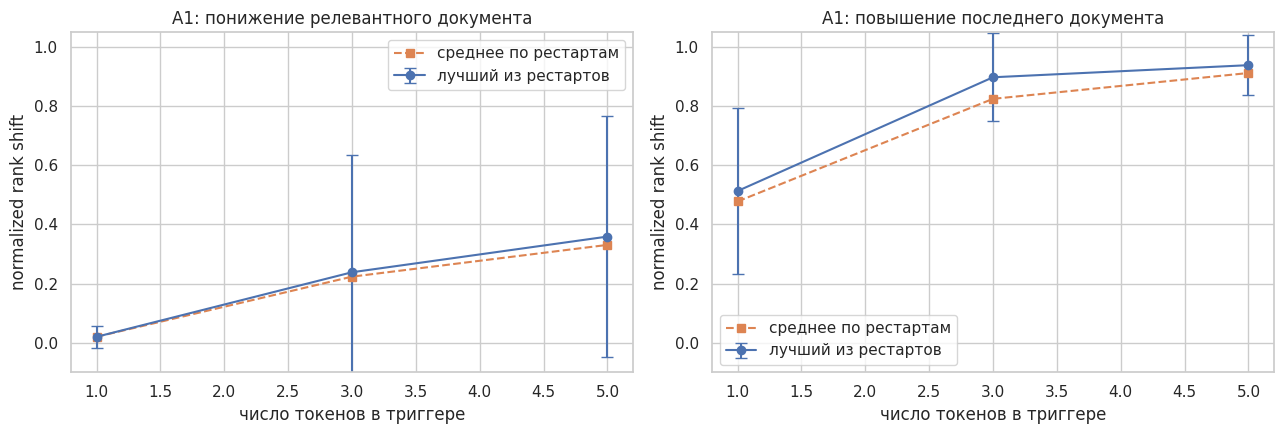

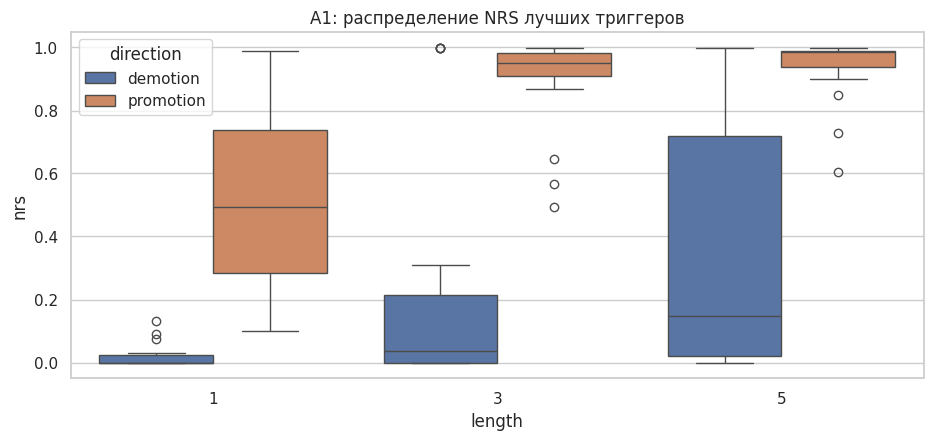

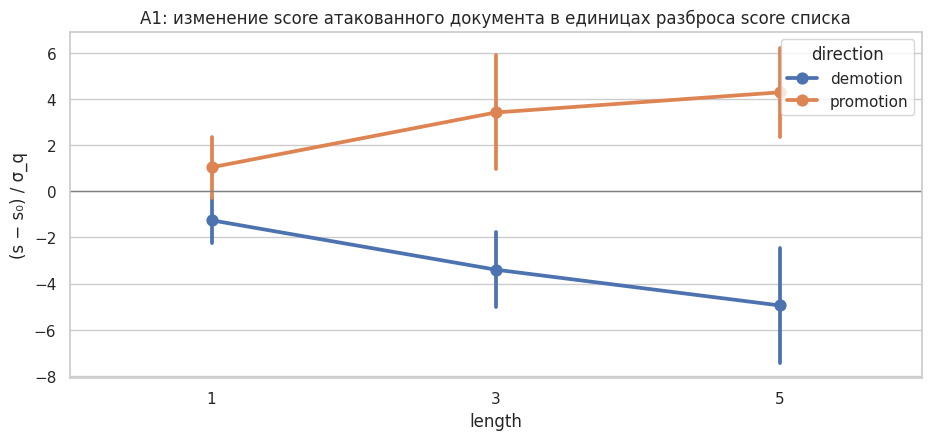

**Самые сильные атаки A1**

,direction,length,query,orig_pos,new_pos,nrs,trigger_text
95,demotion,3,do you keep insulin refrigerated,4,99,1.000,choral nights noun
99,demotion,3,where is florida lo,0,99,1.000,humanist kazan leeds
108,demotion,3,what color is coho salmon meat,3,99,1.000,snooker noun are
111,demotion,3,how long to get a direct deposit paycheck take,1,99,1.000,choral date chorale
174,demotion,5,do you keep insulin refrigerated,4,99,1.000,cremated cremated noun grave definition
178,demotion,5,where is florida lo,0,99,1.000,leicester kazan weather covers leeds
188,demotion,5,what color is coho salmon meat,3,99,1.000,quay eating definition housemates snooker
190,demotion,5,how long to get a direct deposit paycheck take,1,99,1.000,consecration organist rams price days
183,demotion,5,how many days spotting before period is normal,1,90,0.908,does salzburg salzburg passports temperatures
192,demotion,5,what part of the nervous system does adderall affect,0,65,0.657,controlled outlaws meaning rearview looting


In [13]:
A1_best = A1[A1["is_best"]].copy()
t_best = summarize(A1_best, ["direction", "length"])
t_all = A1.groupby(["direction", "length"]).agg(nrs_mean_all_restarts=("nrs", "mean"),
                                                 nrs_std_all_restarts=("nrs", "std")).reset_index()
A1_table = t_best.merge(t_all, on=["direction", "length"])
display(Markdown("**A1. Лучший триггер из рестартов и среднее по всем рестартам** (как best set / trigger_loss_mean в статье)"))
save_table(A1_table, "A1_length_summary")

thr = []
for (direction, L), g in A1_best.groupby(["direction", "length"]):
    thr.append(dict(direction=direction, length=L, **{f"NRS≥{p}": float((g["nrs"] >= p).mean()) for p in (0.1, 0.25, 0.5, 0.75, 0.9, 1.0)}))
save_table(pd.DataFrame(thr), "A1_length_thresholds")


impact = []
for (direction, L), g in A1_best.groupby(["direction", "length"]):
    if direction == "demotion":
        impact.append(dict(direction=direction, length=L, n=len(g),
                           relevant_was_top1=float((g["orig_pos"] == 0).mean()),
                           relevant_still_top1=float((g["new_pos"] == 0).mean()),
                           relevant_left_top10=float((g["new_pos"] >= 10).mean()),
                           relevant_below_50=float((g["new_pos"] >= 50).mean()),
                           mean_new_pos=float(g["new_pos"].mean())))
    else:
        impact.append(dict(direction=direction, length=L, n=len(g),
                           entered_top50=float((g["new_pos"] < 50).mean()),
                           entered_top10=float((g["new_pos"] < 10).mean()),
                           became_top1=float((g["new_pos"] == 0).mean()),
                           mean_new_pos=float(g["new_pos"].mean())))
display(Markdown("**Влияние на выдачу**: понижение релевантного документа и продвижение нерелевантного"))
save_table(pd.DataFrame(impact), "A1_length_ranking_impact")


conv = A1.groupby(["direction", "length"]).agg(iterations_mean=("iterations", "mean"), iterations_max=("iterations", "max"),
                                               runtime_s_mean=("runtime_s", "mean")).reset_index()
best_init = A1_best.groupby(["direction", "length"])["init"].apply(lambda s: float((s == "mask").mean())).rename("best_is_mask_init").reset_index()
save_table(conv.merge(best_init, on=["direction", "length"]), "A1_length_convergence")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, direction in zip(axes, ("demotion", "promotion")):
    d = A1_table[A1_table["direction"] == direction]
    ax.errorbar(d["length"], d["nrs_mean"], yerr=d["nrs_std"], marker="o", capsize=4, label="лучший из рестартов")
    ax.plot(d["length"], d["nrs_mean_all_restarts"], marker="s", ls="--", label="среднее по рестартам")
    ax.set_title(f"A1: {'понижение релевантного' if direction == 'demotion' else 'повышение последнего'} документа")
    ax.set_xlabel("число токенов в триггере")
    ax.set_ylabel("normalized rank shift")
    ax.set_ylim(-0.1, 1.05)
    ax.legend()
plt.tight_layout()
savefig(fig, "A1_nrs_vs_length")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=A1_best, x="length", y="nrs", hue="direction", ax=ax)
ax.set_title("A1: распределение NRS лучших триггеров")
savefig(fig, "A1_nrs_boxplot")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.pointplot(data=A1_best, x="length", y="norm_score_delta", hue="direction", errorbar="sd", ax=ax)
ax.axhline(0, color="grey", lw=1)
ax.set_ylabel("(s − s₀) / σ_q")
ax.set_title("A1: изменение score атакованного документа в единицах разброса score списка")
savefig(fig, "A1_score_delta")

display(Markdown("**Самые сильные атаки A1**"))
cols = ["direction", "length", "query", "orig_pos", "new_pos", "nrs", "trigger_text"]
save_table(A1_best.sort_values(["direction", "nrs"], ascending=[True, False]).groupby("direction").head(10)[cols], "A1_examples", round_=3)

In [14]:
EXP = "A2_position"
done = done_keys(EXP)
finish = stage_timer(EXP)
L = CFG["position_trigger_len"]
skipped_short = 0
for direction in ("demotion", "promotion"):
    for qid in tqdm(Q_POSITION, desc=f"A2 {direction}"):
        r = RANKLISTS[qid]
        rank_index = r["relevant_rank"] if direction == "demotion" else len(r["doc_ids"]) - 1
        t = make_target(qid, rank_index)
        n = len(t["body0"])
        if n < L + 2:
            skipped_short += 1
            continue
        rng = rng_for(EXP, direction, qid)
        _, g0 = score_and_grad(t["body0"], t["qv"])
        gsum = g0.sum(-1).cpu().numpy()         
        c = n // 2
        positions = {
            "start": list(range(L)),
            "middle": list(range(c - L // 2, c - L // 2 + L)),
            "end": list(range(n - L, n)),
            "random": sorted(int(x) for x in rng.choice(n, size=L, replace=False)),
            "max_grad": sorted(int(x) for x in np.argsort(-gsum)[:L]),
            "min_grad": sorted(int(x) for x in np.argsort(gsum)[:L]),
        }
        plan = [(m, "replace", positions[m]) for m in CFG["position_modes"]] + [("prepend_insert", "prepend", None)]
        for pos_mode, mode, pos in plan:
            key = f"{direction}|{qid}|{pos_mode}"
            if key in done:
                continue
            rows = attack_local(t, direction, L, mode=mode, positions=pos, restarts=CFG["position_restarts"],
                                max_iters=CFG["position_max_iters"], init="mask_first", rng=rng_for(EXP, key),
                                exp=EXP, key=key, position_mode=pos_mode, doc_len=n)
            append_jsonl(RECORD_DIR / f"{EXP}.jsonl", rows)
finish()
print("Пропущено коротких документов:", skipped_short)
A2 = load_records(EXP)
print("Записей:", len(A2))

A2 demotion:   0%|          | 0/15 [00:00<?, ?it/s]

A2 promotion:   0%|          | 0/15 [00:00<?, ?it/s]

A2_position: 9.9 мин; прямых проходов по документам: float32 420, float16 271173; проходов с градиентом 1352
Пропущено коротких документов: 0
Записей: 210


**A2. Эффективность по позиции триггера** (5 токенов)

,direction,position_mode,n,nrs_mean,nrs_std,nrs_median,success_rate,nrs_ge_0_5,full_shift_rate,harmful_rate,orig_pos_mean,new_pos_mean,rank_shift_mean,norm_score_delta_mean,iterations_mean,runtime_s_mean
4,demotion,prepend_insert,15,0.3202,0.4016,0.1111,0.9333,0.2667,0.2000,0.0,0.6667,31.8000,31.1333,-4.9496,6.3333,3.0634
6,demotion,start,15,0.3198,0.3732,0.1919,0.9333,0.2000,0.2000,0.0,0.6667,31.8000,31.1333,-4.8949,5.8000,2.7880
2,demotion,middle,15,0.2130,0.3581,0.0103,0.6000,0.2000,0.1333,0.0,0.6667,21.2667,20.6000,-3.2006,6.7333,3.0784
0,demotion,end,15,0.1354,0.3511,0.0000,0.3333,0.1333,0.1333,0.0,0.6667,13.6000,12.9333,-1.6865,7.5333,3.4860
5,demotion,random,15,0.1432,0.3133,0.0101,0.5333,0.1333,0.0667,0.0,0.6667,14.4000,13.7333,-2.8042,5.9333,2.8273
1,demotion,max_grad,15,0.3170,0.4356,0.0505,0.8667,0.2667,0.2667,0.0,0.6667,31.4667,30.8000,-4.3292,5.4667,2.6335
3,demotion,min_grad,15,0.4274,0.4700,0.1818,0.9333,0.4000,0.3333,0.0,0.6667,42.3333,41.6667,-4.8977,5.6000,2.5751
11,promotion,prepend_insert,15,0.9313,0.1137,0.9899,1.0000,1.0000,0.0667,0.0,99.0000,6.8000,92.2000,3.7567,6.7333,2.8902
13,promotion,start,15,0.8633,0.2688,0.9798,0.9333,0.9333,0.1333,0.0,99.0000,13.5333,85.4667,4.1601,7.7333,3.4280
9,promotion,middle,15,0.8532,0.1968,0.9798,1.0000,0.9333,0.1333,0.0,99.0000,14.5333,84.4667,3.4205,5.9333,2.4159


**Сравнение с заменой первых токенов (start)** на тех же парах

,direction,position_mode,n,mean_minus_start,share_better_than_start,mannwhitney_p
0,demotion,end,15,-0.1844,0.0000,0.0024
1,demotion,max_grad,15,-0.0028,0.2667,0.6603
2,demotion,middle,15,-0.1068,0.0000,0.1068
3,demotion,min_grad,15,0.1076,0.2667,0.8011
4,demotion,prepend_insert,15,0.0004,0.2000,0.8344
5,demotion,random,15,-0.1766,0.0667,0.0195
6,promotion,end,15,-0.0700,0.1333,0.1688
7,promotion,max_grad,15,0.0215,0.2667,0.4034
8,promotion,middle,15,-0.0101,0.2000,0.5998
9,promotion,min_grad,15,-0.0754,0.2667,0.4889


,direction,position_mode,count,mean,std,min,25%,50%,75%,max
0,demotion,max_grad,15.0,0.3889,0.1606,0.1464,0.2780,0.3625,0.4945,0.6943
1,demotion,min_grad,15.0,0.3763,0.1633,0.1521,0.2655,0.3287,0.5025,0.7286
2,promotion,max_grad,15.0,0.3526,0.1265,0.0648,0.3035,0.3580,0.4620,0.4938
3,promotion,min_grad,15.0,0.3214,0.1300,0.0577,0.2309,0.3667,0.4097,0.5194


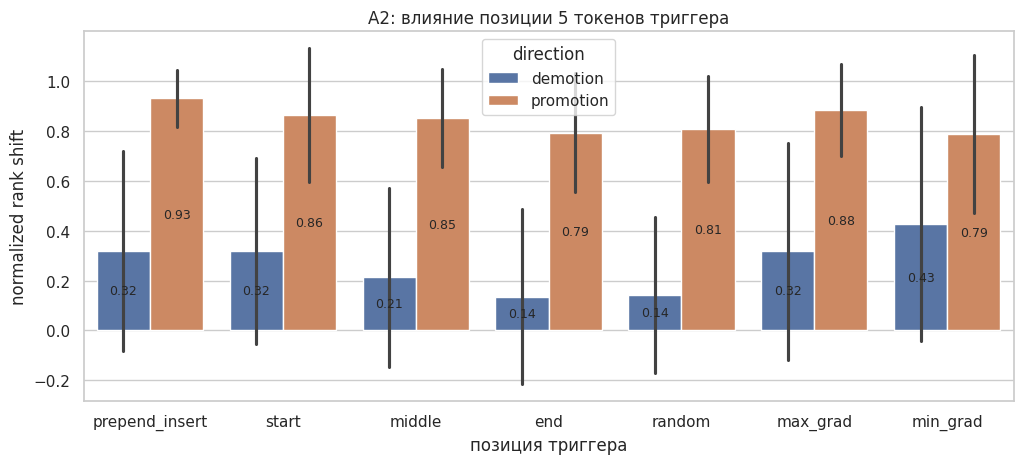

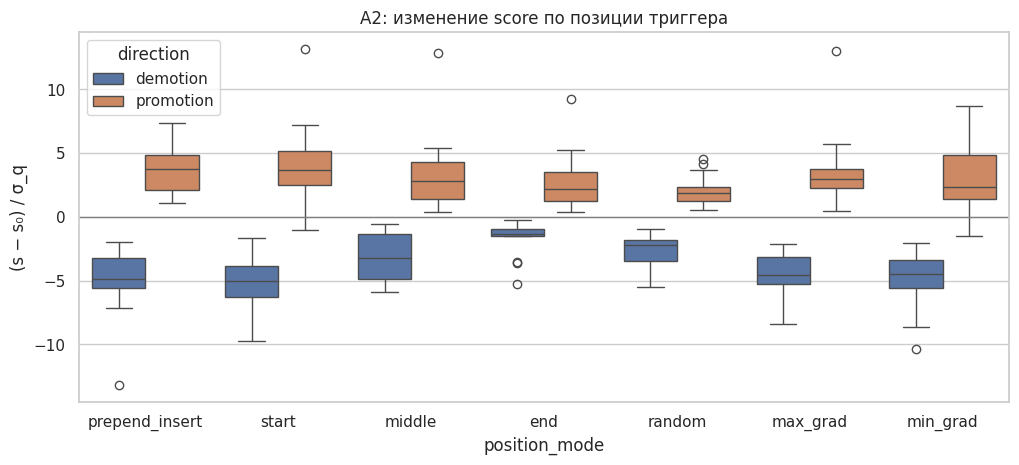

In [15]:
A2_best = A2[A2["is_best"]].copy()
order = ["prepend_insert"] + CFG["position_modes"]
A2_table = summarize(A2_best, ["direction", "position_mode"])
A2_table["position_mode"] = pd.Categorical(A2_table["position_mode"], order)
A2_table = A2_table.sort_values(["direction", "position_mode"])
display(Markdown("**A2. Эффективность по позиции триггера** (5 токенов)"))
save_table(A2_table, "A2_position_summary")

piv = A2_best.pivot_table(index=["direction", "query_id"], columns="position_mode", values="nrs")
cmp_rows = []
for direction in ("demotion", "promotion"):
    if direction not in piv.index.get_level_values(0):
        continue
    p = piv.loc[direction]
    for m in p.columns:
        if m == "start":
            continue
        both = p[["start", m]].dropna()
        if len(both) >= 5 and (both["start"] != both[m]).any():
            stat, pval = mannwhitneyu(both[m], both["start"], alternative="two-sided")
        else:
            pval = np.nan
        cmp_rows.append(dict(direction=direction, position_mode=m, n=len(both), mean_minus_start=float((both[m] - both["start"]).mean()),
                             share_better_than_start=float((both[m] > both["start"]).mean()), mannwhitney_p=pval))
display(Markdown("**Сравнение с заменой первых токенов (start)** на тех же парах"))
save_table(pd.DataFrame(cmp_rows), "A2_position_vs_start")

# Чем отличаются выбранные позиции: где в документе стоят градиентные позиции
gpos = A2_best[A2_best["position_mode"].isin(["max_grad", "min_grad"])].copy()
if not gpos.empty:
    gpos["relative_position"] = gpos.apply(lambda r: np.mean(r["positions"]) / max(r["doc_len"] - 1, 1), axis=1)
    save_table(gpos.groupby(["direction", "position_mode"])["relative_position"].describe().reset_index(), "A2_gradient_positions")

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.barplot(data=A2_best, x="position_mode", y="nrs", hue="direction", order=order, errorbar="sd", ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", label_type="center", fontsize=9)
ax.set_xlabel("позиция триггера")
ax.set_ylabel("normalized rank shift")
ax.set_title("A2: влияние позиции 5 токенов триггера")
savefig(fig, "A2_nrs_by_position")

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.boxplot(data=A2_best, x="position_mode", y="norm_score_delta", hue="direction", order=order, ax=ax)
ax.axhline(0, color="grey", lw=1)
ax.set_ylabel("(s − s₀) / σ_q")
ax.set_title("A2: изменение score по позиции триггера")
savefig(fig, "A2_score_delta_by_position")

In [16]:
EXP = "A3_multi"
done = done_keys(EXP)
finish = stage_timer(EXP)
L = CFG["multi_trigger_len"]
half = CFG["rank_depth"] // 2
for direction in ("demotion", "promotion"):
    lo, hi = (0, half) if direction == "demotion" else (half, CFG["rank_depth"])
    for qid in tqdm(Q_MULTI, desc=f"A3 local+random {direction}"):
        rng = rng_for(EXP, direction, qid)
        ranks = sorted(int(x) for x in rng.choice(np.arange(lo, hi), size=min(CFG["docs_per_query"], hi - lo), replace=False))
        for rank_index in ranks:
            key = f"{direction}|{qid}|{rank_index}"
            if key in done:
                continue
            t = make_target(qid, rank_index)
            rows = attack_local(t, direction, L, mode="prepend", restarts=CFG["multi_restarts"], max_iters=CFG["multi_max_iters"],
                                init="random", rng=rng_for(EXP, key, "local"), exp=EXP, key=key, position_mode="prepend")
            rows += attack_random(t, direction, L, CFG["n_random_seeds"], rng_for(EXP, key, "random"), exp=EXP, key=key,
                                  position_mode="prepend")
            append_jsonl(RECORD_DIR / f"{EXP}.jsonl", rows)

GLOBAL_TRIGGERS = []
for b in range(CFG["n_global_batches"]):
    for direction in ("demotion", "promotion"):
        key = f"global|{direction}|{b}"
        if key in done:
            continue
        rng = rng_for(EXP, key)
        lo, hi = (0, half) if direction == "demotion" else (half, CFG["rank_depth"])
        qs = [int(x) for x in rng.choice(Q_GLOBAL_POOL, size=min(CFG["global_batch_size"] + CFG["global_heldout"], len(Q_GLOBAL_POOL)), replace=False)]
        batch_q, held_q = qs[:CFG["global_batch_size"]], qs[CFG["global_batch_size"]:]
        batch_t = [make_target(q, int(rng.integers(lo, hi))) for q in batch_q]
        held_t = [make_target(q, int(rng.integers(lo, hi))) for q in held_q]
        rows, trig = attack_global(batch_t, direction, L, restarts=CFG["global_restarts"], max_iters=CFG["multi_max_iters"],
                                   rng=rng, exp=EXP, key=key, position_mode="prepend", global_batch=b)
        if held_t:
            rows += evaluate_fixed_trigger(held_t, direction, trig, method="global_heldout", exp=EXP, key=key,
                                           position_mode="prepend", global_batch=b, is_best=True)
        append_jsonl(RECORD_DIR / f"{EXP}.jsonl", rows)
finish()
A3 = load_records(EXP)
print("Записей:", len(A3))

A3 local+random demotion:   0%|          | 0/15 [00:00<?, ?it/s]

A3 local+random promotion:   0%|          | 0/15 [00:00<?, ?it/s]

A3_multi: 4.8 мин; прямых проходов по документам: float32 1626, float16 104461; проходов с градиентом 848
Записей: 1056


**A3. Local / global / random** (3 токена в начале документа)

,direction,method_label,n,nrs_mean,nrs_std,nrs_median,success_rate,nrs_ge_0_5,full_shift_rate,harmful_rate,orig_pos_mean,new_pos_mean,rank_shift_mean,norm_score_delta_mean,iterations_mean,runtime_s_mean
3,demotion,random,300,0.1135,0.2527,0.0319,0.6000,0.0833,0.0333,0.2433,24.4500,32.0067,7.5567,-0.1930,0.0000,0.0080
0,demotion,global,24,0.6694,0.4131,1.0000,1.0000,0.6250,0.5417,0.0000,18.3750,69.7083,51.3333,-1.6523,5.0000,1.9691
1,demotion,global (held-out),144,0.5933,0.4062,0.6386,0.9583,0.5833,0.3958,0.0208,23.2014,65.6736,42.4722,-1.2087,0.0000,NaN
2,demotion,local,60,0.8681,0.2955,1.0000,1.0000,0.8667,0.8167,0.0000,24.4500,87.1667,62.7167,-2.1364,4.7000,1.4486
7,promotion,random,300,-0.0812,0.2716,-0.0761,0.3000,0.0300,0.0000,0.6533,75.3333,80.3433,-5.0100,-0.1089,0.0000,0.0072
4,promotion,global,24,0.3132,0.4717,0.2582,0.7500,0.4167,0.0000,0.2500,76.6667,50.3750,26.2917,0.5867,5.3333,2.1957
5,promotion,global (held-out),144,-0.0023,0.3178,0.0000,0.4653,0.0486,0.0000,0.4653,72.6875,71.6528,1.0347,-0.0015,0.0000,NaN
6,promotion,local,60,0.8177,0.2480,0.9443,1.0000,0.8500,0.1000,0.0000,75.3333,13.8500,61.4833,2.9209,5.3000,1.4211


,direction,method,n,n_random,mean_diff_vs_random,mannwhitney_p_greater
0,demotion,global,24,300,0.555928,0.000000
1,demotion,global (held-out),144,300,0.479808,0.000000
2,demotion,local,60,300,0.754653,0.000000
3,promotion,global,24,300,0.394392,0.000003
4,promotion,global (held-out),144,300,0.078886,0.000566
5,promotion,local,60,300,0.898891,0.000000


,direction,method_label,orig_bucket,size,mean,std
0,demotion,global,1–10,6,0.2398,0.3828
1,demotion,global,11–25,11,0.8024,0.3452
2,demotion,global,26–50,7,0.8286,0.2949
3,demotion,global (held-out),1–10,36,0.3233,0.3452
4,demotion,global (held-out),11–25,40,0.5873,0.3939
5,demotion,global (held-out),26–50,68,0.7397,0.3723
6,demotion,local,1–10,12,0.5281,0.4441
7,demotion,local,11–25,17,0.9537,0.1910
8,demotion,local,26–50,31,0.9528,0.1489
9,demotion,random,1–10,60,0.0524,0.1173


**Глобальные триггеры**: средний NRS на своей пачке и на других парах

,direction,global_batch,trigger,nrs_in_batch,objective,nrs_heldout
0,demotion,0.0,choral choral means,0.635,-1.577,0.675
1,demotion,1.0,gershwin gershwin cost,0.634,-1.822,0.517
2,demotion,2.0,kazakh kazakh cost,0.740,-1.558,0.587
3,promotion,0.0,test sc ryan,0.294,0.759,-0.112
4,promotion,1.0,andrei archasian,0.392,0.572,0.036
5,promotion,2.0,erasmus noun−1,0.254,0.429,0.069


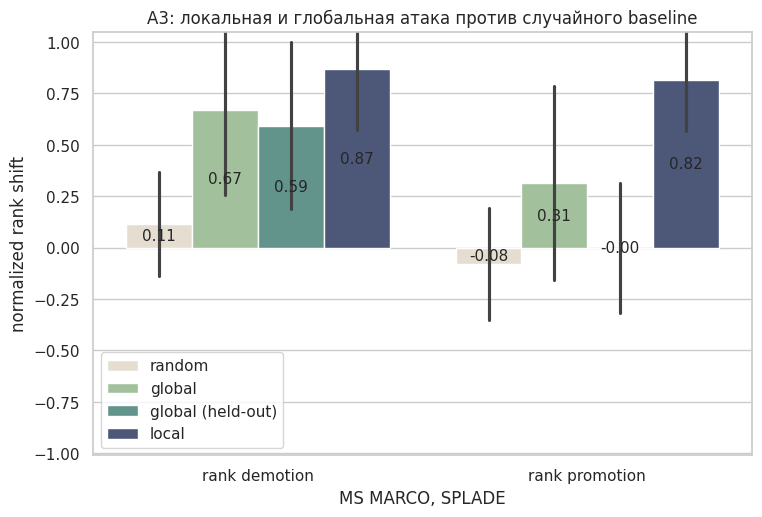

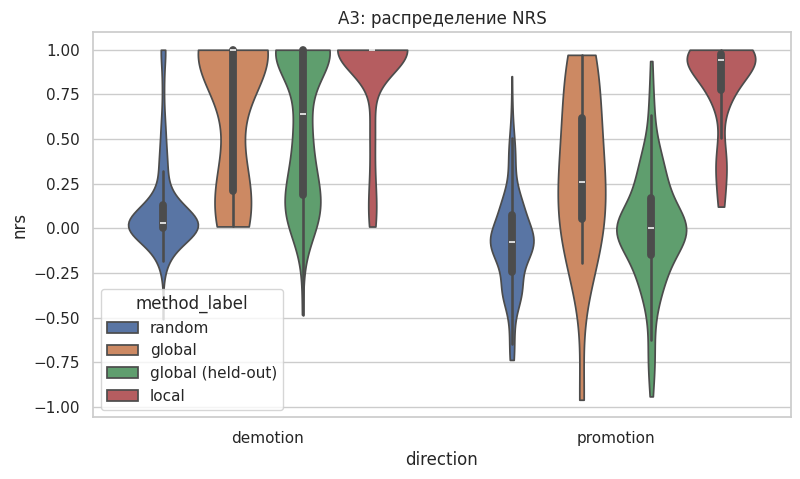

In [17]:
A3 = load_records("A3_multi")
local_rows = A3[(A3["method"] == "local") & A3["is_best"]]
random_rows = A3[A3["method"] == "random"]
global_rows = A3[(A3["method"] == "global") & A3["is_best"]]
held_rows = A3[A3["method"] == "global_heldout"]
A3_plot = pd.concat([random_rows.assign(method_label="random"), global_rows.assign(method_label="global"),
                     held_rows.assign(method_label="global (held-out)"), local_rows.assign(method_label="local")], ignore_index=True)
A3_plot["direction_label"] = A3_plot["direction"].map({"demotion": "rank demotion", "promotion": "rank promotion"})
method_order = ["random", "global", "global (held-out)", "local"]

A3_table = summarize(A3_plot, ["direction", "method_label"])
A3_table["method_label"] = pd.Categorical(A3_table["method_label"], method_order)
A3_table = A3_table.sort_values(["direction", "method_label"])
display(Markdown("**A3. Local / global / random** (3 токена в начале документа)"))
save_table(A3_table, "A3_methods_summary")

tests = []
for direction in ("demotion", "promotion"):
    base = A3_plot[(A3_plot["direction"] == direction) & (A3_plot["method_label"] == "random")]["nrs"]
    for m in ("global", "global (held-out)", "local"):
        x = A3_plot[(A3_plot["direction"] == direction) & (A3_plot["method_label"] == m)]["nrs"]
        if len(x) >= 3 and len(base) >= 3:
            stat, p = mannwhitneyu(x, base, alternative="greater")
            tests.append(dict(direction=direction, method=m, n=len(x), n_random=len(base),
                              mean_diff_vs_random=float(x.mean() - base.mean()), mannwhitney_p_greater=float(p)))
save_table(pd.DataFrame(tests), "A3_significance", round_=6)


A3_plot["orig_bucket"] = pd.cut(A3_plot["orig_pos"], [-1, 9, 24, 49, 74, 100], labels=["1–10", "11–25", "26–50", "51–75", "76–100"])
save_table(A3_plot.groupby(["direction", "method_label", "orig_bucket"], observed=True)["nrs"].agg(["size", "mean", "std"]).reset_index(),
           "A3_by_original_position")


if not global_rows.empty:
    g_trig = (global_rows.groupby(["direction", "global_batch"])
              .agg(trigger=("trigger_text", "first"), nrs_in_batch=("nrs", "mean"), objective=("global_objective", "first")).reset_index())
    if not held_rows.empty:
        g_trig = g_trig.merge(held_rows.groupby(["direction", "global_batch"])["nrs"].mean().rename("nrs_heldout").reset_index(),
                              on=["direction", "global_batch"], how="left")
    display(Markdown("**Глобальные триггеры**: средний NRS на своей пачке и на других парах"))
    save_table(g_trig, "A3_global_triggers", round_=3)

palette = sns.cubehelix_palette(8, start=0.5, rot=-0.85, gamma=0.8)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.barplot(data=A3_plot, x="direction_label", y="nrs", hue="method_label", hue_order=method_order,
            order=["rank demotion", "rank promotion"], errorbar="sd", palette=palette[0:8:2], ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", label_type="center", fontsize=11)
ax.set_ylabel("normalized rank shift")
ax.set_xlabel("MS MARCO, SPLADE")
ax.set_ylim(min(-0.1, A3_plot["nrs"].min() - 0.05), 1.05)
ax.legend(title="")
ax.set_title("A3: локальная и глобальная атака против случайного baseline")
savefig(fig, "A3_methods_barplot")

fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=A3_plot, x="direction", y="nrs", hue="method_label", hue_order=method_order, cut=0, ax=ax)
ax.set_title("A3: распределение NRS")
savefig(fig, "A3_methods_violin")

Text-level check:   0%|          | 0/240 [00:00<?, ?it/s]

text_check: 0.0 мин; прямых проходов по документам: float32 0, float16 0; проходов с градиентом 0


**Атака по id против атаки по тексту**

,exp,direction,n,nrs_ids_mean,nrs_text_mean,success_ids,success_text,same_success,trigger_retokenized_same,abs_score_diff_mean,spearman_nrs
0,A1_length,demotion,60,0.2057,0.2029,0.6667,0.65,0.9833,0.9333,0.2068,0.9809
1,A1_length,promotion,60,0.7833,0.7636,1.0000,1.00,1.0000,0.9500,0.2591,0.9587
2,A3_multi,demotion,60,0.8681,0.8681,1.0000,1.00,1.0000,1.0000,0.0000,1.0000
3,A3_multi,promotion,60,0.8177,0.8126,1.0000,1.00,1.0000,0.9500,0.1418,0.9937


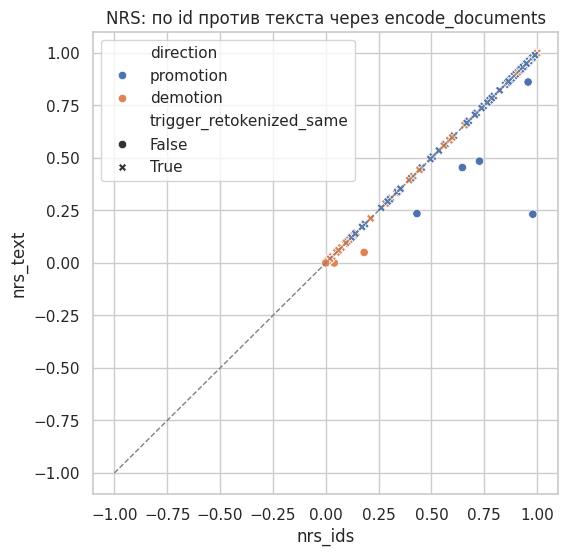

In [18]:
finish = stage_timer("text_check")
cand = pd.concat([A1[A1["is_best"]], A3[(A3["method"] == "local") & A3["is_best"]]], ignore_index=True)
cand = cand.sample(n=min(CFG["text_check"], len(cand)), random_state=CFG["seed"]) if len(cand) else cand
text_rows = []
for _, row in tqdm(cand.iterrows(), total=len(cand), desc="Text-level check"):
    r = RANKLISTS[int(row["query_id"])]
    others = np.delete(r["scores"], int(row["index_rank"]))
    adv_text = tokenizer.decode(row["trigger_ids"]) + " " + doc_texts[int(row["target_doc_id"])]
    retok = tokenizer.encode(adv_text, add_special_tokens=False, verbose=False)[:len(row["trigger_ids"])]
    vec = to_numpy(model.encode_documents([adv_text], batch_size=1))[0]
    s_text = float(vec @ r["q_vec"])
    s_orig = float(row["index_score"])
    pos0, pos1 = rank_of(s_orig, others), rank_of(s_text, others)
    text_rows.append(dict(exp=row["exp"], direction=row["direction"], length=row["length"], nrs_ids=row["nrs"],
                          nrs_text=normalized_rank_shift(row["direction"], pos0, pos1, len(r["scores"])),
                          new_pos_ids=row["new_pos"], new_pos_text=pos1, score_ids=row["new_score"], score_text=s_text,
                          trigger_retokenized_same=bool(retok == list(row["trigger_ids"]))))
text_check = pd.DataFrame(text_rows)
finish()
if not text_check.empty:
    text_check["abs_score_diff"] = (text_check["score_text"] - text_check["score_ids"]).abs()
    text_check["success_ids"] = text_check["nrs_ids"] > 0
    text_check["success_text"] = text_check["nrs_text"] > 0
    tc = text_check.groupby(["exp", "direction"]).agg(
        n=("nrs_ids", "size"), nrs_ids_mean=("nrs_ids", "mean"), nrs_text_mean=("nrs_text", "mean"),
        success_ids=("success_ids", "mean"), success_text=("success_text", "mean"),
        same_success=("success_ids", lambda s: float((s == text_check.loc[s.index, "success_text"]).mean())),
        trigger_retokenized_same=("trigger_retokenized_same", "mean"), abs_score_diff_mean=("abs_score_diff", "mean")).reset_index()
    tc["spearman_nrs"] = [spearmanr(g["nrs_ids"], g["nrs_text"]).correlation if len(g) > 2 else np.nan
                          for _, g in text_check.groupby(["exp", "direction"])]
    display(Markdown("**Атака по id против атаки по тексту**"))
    save_table(tc, "text_level_check")
    text_check.to_csv(TABLE_DIR / "text_level_check_rows.csv", index=False)

    fig, ax = plt.subplots(figsize=(6, 6))
    sns.scatterplot(data=text_check, x="nrs_ids", y="nrs_text", hue="direction", style="trigger_retokenized_same", ax=ax)
    ax.plot([-1, 1], [-1, 1], color="grey", lw=1, ls="--")
    ax.set_title("NRS: по id против текста через encode_documents")
    savefig(fig, "text_level_check")

In [19]:
finish = stage_timer("token_influence")
best_all = pd.concat([
    A1[A1["is_best"]],
    A2[A2["is_best"]] if "A2" in globals() and not A2.empty else None,
    A3[(A3["method"].isin(["local", "global"])) & A3["is_best"]] if not A3.empty else None,
], ignore_index=True)
best_all["n_trigger_tokens"] = best_all["trigger_ids"].apply(len)


expl = best_all[["exp", "method", "direction", "query_id", "nrs", "trigger_ids"]].explode("trigger_ids").rename(columns={"trigger_ids": "token_id"})
expl["token_id"] = expl["token_id"].astype(int)
expl = expl[expl["token_id"] != MASK_ID]
freq = (expl.groupby(["direction", "token_id"])
        .agg(n_triggers=("nrs", "size"), n_queries=("query_id", "nunique"), n_experiments=("exp", "nunique"),
             mean_nrs_with_token=("nrs", "mean")).reset_index())

loo_src = best_all.sort_values("nrs", ascending=False)
loo_src = pd.concat([loo_src[loo_src["direction"] == d].head(CFG["loo_records"] // 2) for d in ("demotion", "promotion")])
loo_rows, decomp_rows = [], []
term_gain = {d: torch.zeros(VOCAB, device=device) for d in ("demotion", "promotion")}
for _, row in tqdm(loo_src.iterrows(), total=len(loo_src), desc="Leave-one-out"):
    t = make_target(int(row["query_id"]), int(row["index_rank"]))
    trig = [int(x) for x in row["trigger_ids"]]
    mode = row.get("mode", "prepend") or "prepend"
    pos = row.get("positions")
    pos = [int(p) for p in pos] if isinstance(pos, list) else None
    full_body = make_body_fn(t["body0"], mode, pos)(trig)
    bodies = []
    for i in range(len(trig)):
        if mode == "prepend":
            bodies.append(make_body_fn(t["body0"], "prepend")(trig[:i] + trig[i + 1:]))
        else:
            bodies.append(make_body_fn(t["body0"], "replace", pos[:i] + pos[i + 1:])(trig[:i] + trig[i + 1:]))
    sc = score_bodies([full_body] + bodies, t["qv"])
    s_full, s_wo = sc[0], sc[1:]
    sign = 1.0 if row["direction"] == "promotion" else -1.0
    for i, tok in enumerate(trig):
        pos_wo = rank_of(s_wo[i], t["others"])
        nrs_wo = normalized_rank_shift(row["direction"], t["orig_pos"], pos_wo, t["n_docs"])
        loo_rows.append(dict(direction=row["direction"], exp=row["exp"], query_id=int(row["query_id"]), token_id=tok,
                             loo_contribution=float(sign * (s_full - s_wo[i]) / t["sigma"]),
                             loo_nrs_drop=float(row["nrs"] - nrs_wo)))
    
    reps = splade_reps([t["body0"], full_body])
    delta = t["qv"] * (reps[1] - reps[0])                     # q_t · (d'_t − d_t)
    total = float(delta.sum())
    trig_dims = torch.as_tensor(sorted(set(trig)), device=device)
    in_trigger = float(delta[trig_dims].sum())
    term_gain[row["direction"]] += sign * delta
    q_active = set(torch.nonzero(t["qv"] > 0).flatten().cpu().tolist())
    q_tokens = set(tokenizer.encode(t["query"], add_special_tokens=False))
    decomp_rows.append(dict(direction=row["direction"], exp=row["exp"], nrs=row["nrs"], delta_total=total,
                            delta_from_trigger_dims=in_trigger,
                            share_from_trigger_dims=in_trigger / total if abs(total) > 1e-9 else np.nan,
                            n_dims_changed=int((delta.abs() > 1e-6).sum()),
                            trigger_tokens_active_in_query=float(np.mean([x in q_active for x in trig])),
                            trigger_tokens_in_query_text=float(np.mean([x in q_tokens for x in trig]))))
    del reps, delta

loo = pd.DataFrame(loo_rows)
loo_agg = (loo.groupby(["direction", "token_id"])
           .agg(loo_n=("loo_contribution", "size"), loo_contrib_mean=("loo_contribution", "mean"),
                loo_contrib_sum=("loo_contribution", "sum"), loo_nrs_drop_mean=("loo_nrs_drop", "mean")).reset_index())
decomp = pd.DataFrame(decomp_rows)
finish()

display(Markdown("**Откуда берётся изменение score**: доля от измерений самих токенов триггера и от расширений SPLADE"))
save_table(decomp.groupby(["direction", "exp"]).agg(
    n=("nrs", "size"), delta_total_mean=("delta_total", "mean"),
    share_from_trigger_dims_median=("share_from_trigger_dims", "median"),
    n_dims_changed_mean=("n_dims_changed", "mean"),
    trigger_tokens_active_in_query=("trigger_tokens_active_in_query", "mean"),
    trigger_tokens_in_query_text=("trigger_tokens_in_query_text", "mean")).reset_index(), "token_score_decomposition")

term_rows = []
for d, vec in term_gain.items():
    top = torch.topk(vec, 25)
    for v, i in zip(top.values.cpu().tolist(), top.indices.cpu().tolist()):
        if v > 0:
            term_rows.append(dict(direction=d, term_id=i, term=vocab_tokens[i], gain_towards_attack=v))
display(Markdown("**Измерения словаря, через которые атака сильнее всего меняет score** (сумма `±q_t·Δd_t` по атакам)"))
save_table(pd.DataFrame(term_rows), "top_splade_terms_moved", round_=3)

Leave-one-out:   0%|          | 0/300 [00:00<?, ?it/s]

token_influence: 0.3 мин; прямых проходов по документам: float32 2086, float16 0; проходов с градиентом 0


**Откуда берётся изменение score**: доля от измерений самих токенов триггера и от расширений SPLADE

,direction,exp,n,delta_total_mean,share_from_trigger_dims_median,n_dims_changed_mean,trigger_tokens_active_in_query,trigger_tokens_in_query_text
0,demotion,A1_length,24,-7.5141,-0.0000,14.4583,0.0083,0.0083
1,demotion,A2_position,47,-8.9201,-0.0000,15.1702,0.0000,0.0000
2,demotion,A3_multi,79,-3.9553,-0.0000,10.7848,0.0042,0.0000
3,promotion,A1_length,35,7.4763,0.6694,14.2000,0.4590,0.2590
4,promotion,A2_position,73,6.9285,0.5206,14.3699,0.3753,0.1726
5,promotion,A3_multi,42,7.1247,0.7803,11.3571,0.4762,0.2460


**Измерения словаря, через которые атака сильнее всего меняет score** (сумма `±q_t·Δd_t` по атакам)

,direction,term_id,term,gain_towards_attack
0,demotion,22597,insulin,36.974
1,demotion,11840,salmon,30.021
2,demotion,3609,color,21.634
3,demotion,13428,brake,20.813
4,demotion,13627,brakes,18.363
5,demotion,3516,florida,16.688
6,demotion,3574,meaning,15.958
7,demotion,18423,glucose,14.109
8,demotion,13109,fl,13.793
9,demotion,4003,card,12.334


In [20]:
finish = stage_timer("token_transfer")
half = CFG["rank_depth"] // 2
transfer_rows = []
trng = rng_for("transfer")
for direction in ("demotion", "promotion"):
    lo, hi = (0, half) if direction == "demotion" else (half, CFG["rank_depth"])
    cands = loo_agg[(loo_agg["direction"] == direction) & (loo_agg["token_id"] != MASK_ID)].sort_values("loo_contrib_sum", ascending=False)
    tokens = cands["token_id"].head(CFG["transfer_tokens"]).astype(int).tolist()
    rand_tokens = [int(x) for x in trng.choice(ALLOWED_IDS, size=CFG["transfer_tokens"], replace=False)]
    qs = trng.choice(list(RANKLISTS), size=CFG["transfer_pairs"], replace=True)
    targets = [make_target(int(q), int(trng.integers(lo, hi))) for q in qs]
    Q = torch.stack([t["qv"] for t in targets])
    for kind, toks in (("attack_token", tokens), ("random_token", rand_tokens)):
        for tok in tqdm(toks, desc=f"Transfer {direction} {kind}"):
            S = score_bodies([[tok] + t["body0"][:BODY_MAX - 1] for t in targets], Q, list(range(len(targets))))
            nrs = [normalized_rank_shift(direction, t["orig_pos"], rank_of(s, t["others"]), t["n_docs"]) for t, s in zip(targets, S)]
            z = [(s - t["s0"]) / t["sigma"] * (1 if direction == "promotion" else -1) for t, s in zip(targets, S)]
            transfer_rows.append(dict(direction=direction, kind=kind, token_id=tok, token=vocab_tokens[tok],
                                      transfer_nrs_mean=float(np.mean(nrs)), transfer_success_rate=float(np.mean(np.array(nrs) > 0)),
                                      transfer_score_gain_mean=float(np.mean(z))))
transfer = pd.DataFrame(transfer_rows)
finish()
display(Markdown("**Перенос одного токена на другие пары**: токены атаки против случайных токенов"))
save_table(transfer.groupby(["direction", "kind"])[["transfer_nrs_mean", "transfer_success_rate", "transfer_score_gain_mean"]]
           .agg(["mean", "std", "max"]).reset_index(), "token_transfer_summary")

Transfer demotion attack_token:   0%|          | 0/30 [00:00<?, ?it/s]

Transfer demotion random_token:   0%|          | 0/30 [00:00<?, ?it/s]

Transfer promotion attack_token:   0%|          | 0/30 [00:00<?, ?it/s]

Transfer promotion random_token:   0%|          | 0/30 [00:00<?, ?it/s]

token_transfer: 4.7 мин; прямых проходов по документам: float32 24390, float16 0; проходов с градиентом 0


**Перенос одного токена на другие пары**: токены атаки против случайных токенов

direction          kind transfer_nrs_mean                 transfer_success_rate                transfer_score_gain_mean                
                                        mean     std     max                  mean     std    max                     mean     std     max
0   demotion  attack_token            0.1608  0.0498  0.2640                0.6747  0.0654  0.820                   0.2482  0.0831  0.4244
1   demotion  random_token            0.1036  0.0328  0.1874                0.5943  0.0613  0.720                   0.1620  0.0537  0.3043
2  promotion  attack_token           -0.0745  0.0208 -0.0383                0.2967  0.0527  0.420                  -0.0928  0.0283 -0.0338
3  promotion  random_token           -0.0808  0.0288 -0.0344                0.2982  0.0567  0.405                  -0.1076  0.0514 -0.0537

### Топ-30 токенов: понижение документа

,direction,rank_in_direction,token,token_id,n_triggers,n_queries,mean_nrs_with_token,loo_n,loo_contrib_mean,loo_contrib_sum,loo_nrs_drop_mean,transfer_nrs_mean,transfer_success_rate,splade_doc_df,n_experiments,transfer_score_gain_mean,is_subword
0,demotion,1,means,2965,19,14,0.3943,16,1.1662,18.6589,0.2428,0.1301,0.630,29885,3,0.1819,False
1,demotion,2,definition,6210,14,7,0.4545,11,1.6895,18.5850,0.3398,0.1196,0.630,25064,3,0.1698,False
2,demotion,3,noun,15156,11,7,0.6795,10,1.7250,17.2495,0.2305,0.1504,0.600,3124,3,0.1818,False
3,demotion,4,choral,14564,22,13,0.6002,19,0.6875,13.0621,0.2053,0.1962,0.700,74,2,0.3468,False
4,demotion,5,leeds,7873,3,1,1.0000,3,4.1676,12.5027,0.2088,0.1027,0.580,44,2,0.1727,False
5,demotion,6,gershwin,25600,17,9,0.5972,12,0.8128,9.7537,0.2097,0.1811,0.690,3,2,0.3019,False
6,demotion,7,dog,3899,4,2,0.2121,4,2.2978,9.1912,0.1944,0.1967,0.760,13291,2,0.2937,False
7,demotion,8,climate,4785,6,3,0.2205,3,2.9997,8.9992,0.2492,0.1595,0.680,8963,2,0.2281,False
8,demotion,9,covers,4472,3,2,1.0000,3,2.8574,8.5721,0.0864,0.1267,0.610,294,3,0.1829,False
9,demotion,10,caves,10614,3,1,1.0000,3,2.8456,8.5368,0.7811,0.1262,0.625,237,1,0.1861,False


### Топ-30 токенов: повышение документа

,direction,rank_in_direction,token,token_id,n_triggers,n_queries,mean_nrs_with_token,loo_n,loo_contrib_mean,loo_contrib_sum,loo_nrs_drop_mean,transfer_nrs_mean,transfer_success_rate,splade_doc_df,n_experiments,transfer_score_gain_mean,is_subword
616,promotion,1,diablo,28841,7,1,0.9971,7,8.2258,57.5805,0.2684,-0.0616,0.320,17,2,-0.0918,False
617,promotion,2,bank,2924,8,2,0.9798,8,2.4885,19.9080,0.2437,-0.0525,0.285,3665,2,-0.0620,False
618,promotion,3,spanish,3009,9,1,0.9663,9,1.9885,17.8964,0.2110,-0.1415,0.205,2557,2,-0.1835,False
619,promotion,4,citadel,15364,3,1,0.9871,3,5.3596,16.0788,0.3602,-0.0787,0.320,12,1,-0.1114,False
620,promotion,5,mean,2812,4,1,0.9949,4,3.1200,12.4800,0.0025,-0.1094,0.195,32814,2,-0.1172,False
621,promotion,6,replacement,6110,6,1,0.9949,6,2.0670,12.4019,0.0505,-0.1058,0.245,11359,2,-0.1500,False
622,promotion,7,walter,4787,4,1,0.9874,4,2.9437,11.7750,0.1869,-0.0654,0.300,3858,2,-0.0841,False
623,promotion,8,iron,3707,4,1,0.9625,4,2.9423,11.7691,0.5638,-0.0779,0.260,2345,1,-0.0944,False
624,promotion,9,sur,7505,3,1,0.9899,3,3.7188,11.1563,0.0067,-0.0667,0.305,1376,2,-0.0787,False
625,promotion,10,seat,2835,3,1,0.9865,3,3.5325,10.5975,0.0067,-0.0651,0.345,2918,2,-0.0630,False


**Чем токены атаки отличаются от словаря в целом**

,direction,unique_tokens,subword_share,median_splade_doc_df,median_wackiness,wackiness_known_share
0,demotion,616,0.0406,119.5,NaN,NaN
1,promotion,625,0.1488,197.0,NaN,NaN
2,весь словарь,29523,0.1974,70.0,NaN,NaN


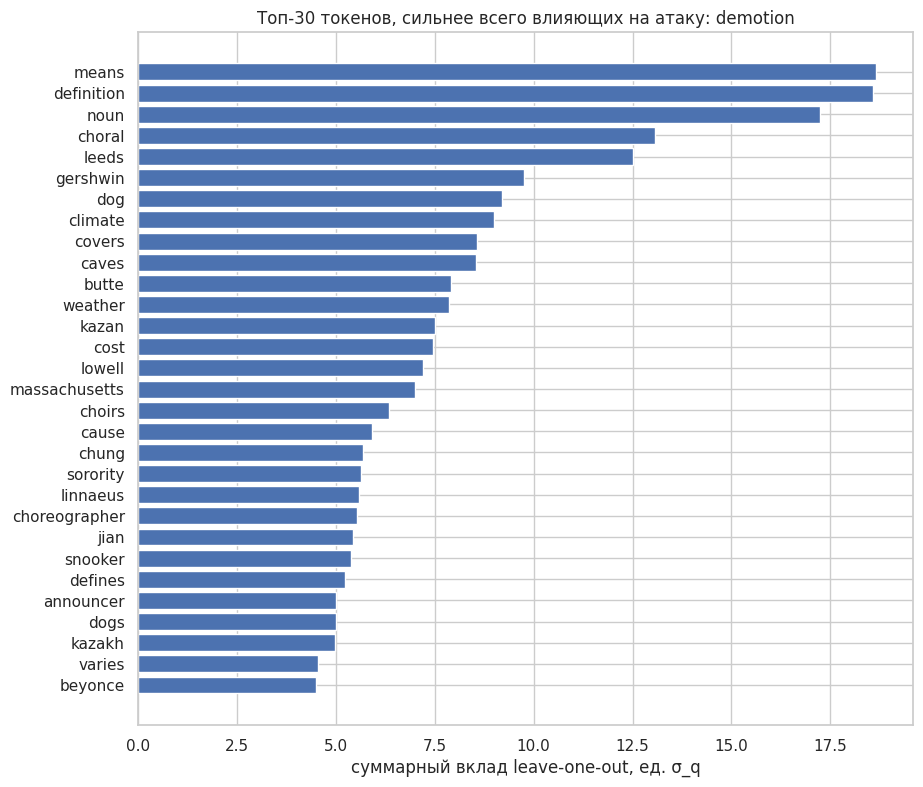

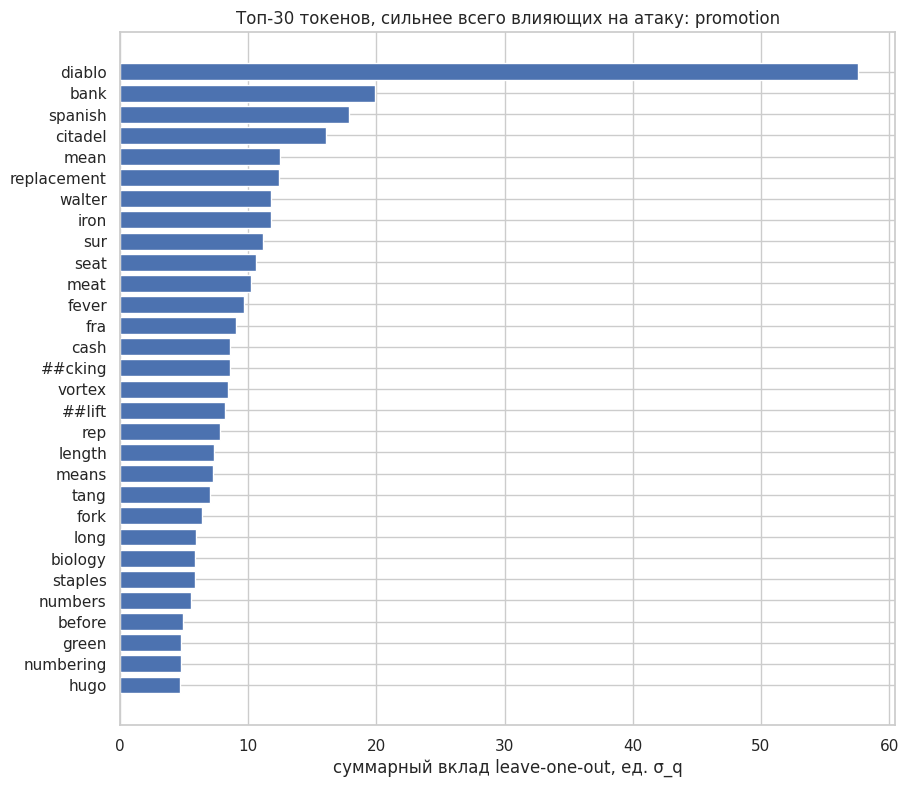

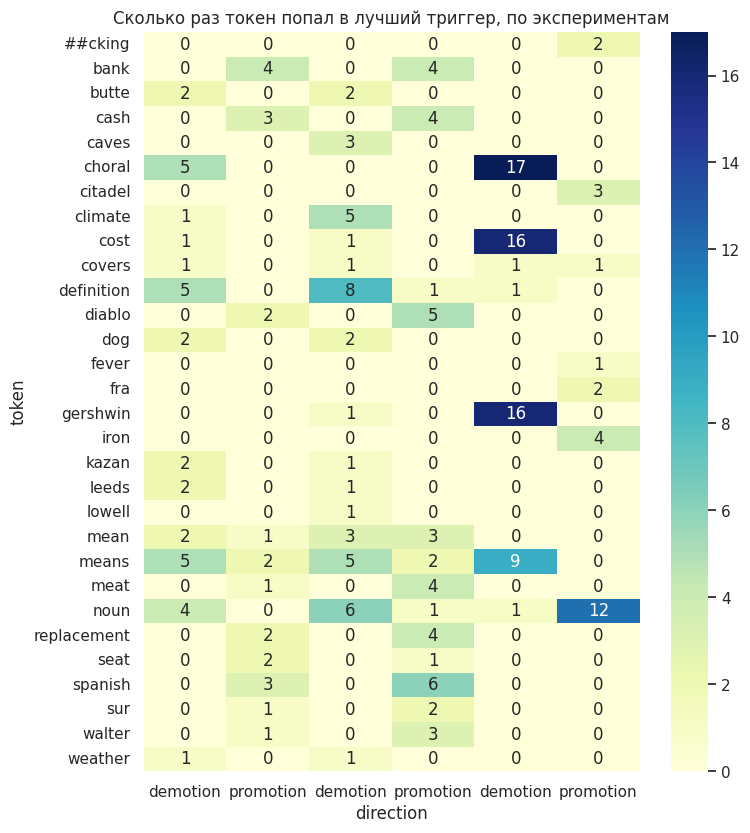

In [21]:

top = freq.merge(loo_agg, on=["direction", "token_id"], how="outer")
top = top.merge(transfer[transfer["kind"] == "attack_token"][["direction", "token_id", "transfer_nrs_mean", "transfer_success_rate",
                                                              "transfer_score_gain_mean"]], on=["direction", "token_id"], how="left")
top = top[top["token_id"].astype(int) != MASK_ID].copy()   
top["token"] = top["token_id"].astype(int).map(lambda i: vocab_tokens[i])
top["splade_doc_df"] = top["token_id"].astype(int).map(lambda i: int(splade_df[i]))
top["is_subword"] = top["token"].str.startswith("##")
if wacky_table is not None:
    w = wacky_table[[c for c in ["token_id", "wackiness_score", "expansion_occurrences", "mean_lexical_utility"] if c in wacky_table.columns]]
    top = top.merge(w, on="token_id", how="left")
if lexical_table is not None:
    top = top.merge(lexical_table[["token_id", "lexical_df", "lexical_idf"]], on="token_id", how="left")
for c in ["n_triggers", "n_queries", "loo_n"]:
    top[c] = top[c].fillna(0).astype(int)
top = top.sort_values(["direction", "loo_contrib_sum", "n_triggers"], ascending=[True, False, False]).reset_index(drop=True)
top["rank_in_direction"] = top.groupby("direction").cumcount() + 1
front = ["direction", "rank_in_direction", "token", "token_id", "n_triggers", "n_queries", "mean_nrs_with_token",
         "loo_n", "loo_contrib_mean", "loo_contrib_sum", "loo_nrs_drop_mean",
         "transfer_nrs_mean", "transfer_success_rate", "splade_doc_df"]
top = top[[c for c in front if c in top.columns] + [c for c in top.columns if c not in front]]
top.to_csv(OUT_DIR / "top_attack_tokens.csv", index=False)
for d in ("demotion", "promotion"):
    top[top["direction"] == d].to_csv(OUT_DIR / f"top_attack_tokens_{d}.csv", index=False)
    display(Markdown(f"### Топ-30 токенов: {'понижение' if d == 'demotion' else 'повышение'} документа"))
    display(top[top["direction"] == d].head(30).round(4))


profile = []
for d in ("demotion", "promotion"):
    toks = top[(top["direction"] == d) & (top["n_triggers"] > 0)]
    profile.append(dict(direction=d, unique_tokens=len(toks), subword_share=float(toks["is_subword"].mean()),
                        median_splade_doc_df=float(toks["splade_doc_df"].median()),
                        median_wackiness=float(toks["wackiness_score"].median()) if "wackiness_score" in toks else np.nan,
                        wackiness_known_share=float(toks["wackiness_score"].notna().mean()) if "wackiness_score" in toks else np.nan))
profile.append(dict(direction="весь словарь", unique_tokens=len(ALLOWED_IDS),
                    subword_share=float(np.mean([vocab_tokens[i].startswith("##") for i in ALLOWED_IDS])),
                    median_splade_doc_df=float(np.median(splade_df[ALLOWED_IDS])),
                    median_wackiness=float(wacky_table["wackiness_score"].median()) if wacky_table is not None else np.nan,
                    wackiness_known_share=float(len(wacky_table) / len(ALLOWED_IDS)) if wacky_table is not None else np.nan))
display(Markdown("**Чем токены атаки отличаются от словаря в целом**"))
save_table(pd.DataFrame(profile), "attack_token_profile")

for d in ("demotion", "promotion"):
    p = top[(top["direction"] == d)].head(30).sort_values("loo_contrib_sum")
    if p.empty:
        continue
    fig, ax = plt.subplots(figsize=(10, max(6, 0.3 * len(p))))
    ax.barh(p["token"].astype(str), p["loo_contrib_sum"])
    ax.set_xlabel("суммарный вклад leave-one-out, ед. σ_q")
    ax.set_title(f"Топ-30 токенов, сильнее всего влияющих на атаку: {d}")
    savefig(fig, f"top_tokens_{d}")

heat_tokens = top.groupby("direction").head(15)["token_id"].astype(int).unique().tolist()
heat = expl[expl["token_id"].isin(heat_tokens)].assign(token=lambda x: x["token_id"].map(lambda i: vocab_tokens[i]))
heat = heat.pivot_table(index="token", columns=["exp", "direction"], values="nrs", aggfunc="size", fill_value=0)
if not heat.empty:
    fig, ax = plt.subplots(figsize=(max(8, 1.3 * heat.shape[1]), max(6, 0.32 * heat.shape[0])))
    sns.heatmap(heat, cmap="YlGnBu", annot=True, fmt="d", ax=ax)
    ax.set_title("Сколько раз токен попал в лучший триггер, по экспериментам")
    savefig(fig, "top_tokens_heatmap")

if "wackiness_score" in top.columns and top["wackiness_score"].notna().any():
    fig, ax = plt.subplots(figsize=(8, 5.5))
    sc = top[top["loo_n"] > 0]
    sns.scatterplot(data=sc, x="wackiness_score", y="loo_contrib_mean", hue="direction", size="n_triggers", ax=ax)
    ax.set_title("Wackiness Score (фаза 1) и вклад токена в атаку (фаза 2)")
    savefig(fig, "wackiness_vs_attack_influence")

In [22]:
runtime = pd.DataFrame(RUNTIME, columns=["stage", "seconds"]).groupby("stage", sort=False)["seconds"].sum().reset_index()
runtime["minutes"] = runtime["seconds"] / 60
save_table(runtime, "runtime", round_=2)

overview = []
for name, df, sel in (("A1 длина (лучшие)", A1, A1["is_best"]), ("A2 позиция (лучшие)", A2, A2["is_best"]),
                      ("A3 local", A3, (A3["method"] == "local") & A3["is_best"]), ("A3 random", A3, A3["method"] == "random"),
                      ("A3 global", A3, (A3["method"] == "global") & A3["is_best"]), ("A3 global held-out", A3, A3["method"] == "global_heldout")):
    part = df[sel]
    for d in ("demotion", "promotion"):
        x = part[part["direction"] == d]["nrs"]
        if len(x):
            overview.append(dict(experiment=name, direction=d, n=len(x), nrs_mean=x.mean(), nrs_median=x.median(),
                                 success_rate=float((x > 0).mean())))
display(Markdown("**Сводка по всем экспериментам**"))
save_table(pd.DataFrame(overview), "overview")

run_config = {
    "phase": "2: adversarial robustness (BERT Rankers are Brittle → SPLADE)",
    "based_on": "https://github.com/menauwy/brittlebert (attack_methods.py, attack_trigger_*.py)",
    "model_dir": str(MODEL_DIR), "checkpoint": str(MODEL_DIR / "model" / "model.pt"),
    "doc_encoder_attr": MLM_ATTR, "doc_encoder_class": type(MLM).__name__,
    "tokenizer": getattr(tokenizer, "name_or_path", type(tokenizer).__name__), "vocab_size": VOCAB,
    "dataset": str(DATA_DIR), "documents": len(documents), "queries_in_pool": len(RANKLISTS),
    "index": index_source, "wackiness_phase1": str(wacky_path) if wacky_path else None,
    "calibration": {"aggregation": DOC_AGG, "max_length": DOC_MAXLEN, "cos_min": float(best_cal["cos_min"]),
                    "max_abs_diff": float(best_cal["max_abs_diff"])},
    "retrieval_sanity": retrieval_sanity, "config": CFG,
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__,
                 "transformers": __import__("transformers").__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "forward_stats": dict(FORWARD_STATS), "final_token_budget": TOKEN_BUDGET,
}
with open(OUT_DIR / "run_config.json", "w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=2, ensure_ascii=False, default=_json_default)
print(json.dumps({k: run_config[k] for k in ("index", "calibration", "retrieval_sanity", "forward_stats")}, indent=2, ensure_ascii=False))

import zipfile
archive = Path("/kaggle/working") / "attack_results_tables.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUT_DIR.rglob("*")):
        if path.is_file() and "index" not in path.relative_to(OUT_DIR).parts:
            zf.write(path, path.relative_to(OUT_DIR))
print("\nФайлы:")
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file() and "index" not in path.relative_to(OUT_DIR).parts:
        print(f"{str(path.relative_to(OUT_DIR)):60s} {path.stat().st_size / 1024:9.1f} KB")
print("\nАрхив:", archive)

,stage,seconds,minutes
0,model_load,1.49,0.02
1,data,5.07,0.08
2,index,1551.14,25.85
3,calibration,3.93,0.07
4,sanity,188.80,3.15
5,ranklists,136.71,2.28
6,A1_length,397.50,6.62
7,A2_position,592.98,9.88
8,A3_multi,285.20,4.75
9,text_check,2.73,0.05


**Сводка по всем экспериментам**

,experiment,direction,n,nrs_mean,nrs_median,success_rate
0,A1 длина (лучшие),demotion,60,0.2057,0.0202,0.6667
1,A1 длина (лучшие),promotion,60,0.7833,0.9293,1.0000
2,A2 позиция (лучшие),demotion,105,0.2680,0.0404,0.7333
3,A2 позиция (лучшие),promotion,105,0.8461,0.9495,0.9810
4,A3 local,demotion,60,0.8681,1.0000,1.0000
5,A3 local,promotion,60,0.8177,0.9443,1.0000
6,A3 random,demotion,300,0.1135,0.0319,0.6000
7,A3 random,promotion,300,-0.0812,-0.0761,0.3000
8,A3 global,demotion,24,0.6694,1.0000,1.0000
9,A3 global,promotion,24,0.3132,0.2582,0.7500


{
  "index": "пересобран в фазе 2 кодом фазы 1",
  "calibration": {
    "aggregation": "max",
    "max_length": 256,
    "cos_min": 0.9999999403953552,
    "max_abs_diff": 9.47900116443634e-06
  },
  "retrieval_sanity": {
    "queries": 500,
    "MRR@10": 0.7761357142857144,
    "Recall@10": 0.942,
    "Recall@100": 0.992,
    "Recall@1000": 0.998,
    "mean_active_query_terms": 20.788
  },
  "forward_stats": {
    "doc_forwards": 29963,
    "grad_passes": 3416,
    "doc_forwards_fp16": 543756
  }
}

Файлы:
plots/A1_nrs_boxplot.png                                          45.7 KB
plots/A1_nrs_vs_length.png                                       106.6 KB
plots/A1_score_delta.png                                          64.8 KB
plots/A2_nrs_by_position.png                                      71.7 KB
plots/A2_score_delta_by_position.png                              59.5 KB
plots/A3_methods_barplot.png                                      75.2 KB
plots/A3_methods_violin.png                